<img src=images/banner_rl.png width=500 >

# **Table of contents**<a id='toc0_'></a>    
- [Discrete Environment](#toc1_)    
  - [Preparing the Custom Environment](#toc1_1_)    
  - [Q-Learning](#toc1_2_)    
  - [Double Q_Learning](#toc1_3_)
  - [Deep Q_Learning](#toc1_4_)
  - [DQN HyperParameter tuning](#toc1_5_)

 
   
- [Continues Environment](#toc2_)    
  - [Preparing the Environment](#toc2_1_)    
  - [DQN](#toc2_2_) 
  - [DDPG](#toc2_3_) 

- [Evaluation and Comparison](#toc3_)    
---


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import gymnasium as gym
from gymnasium import Env, spaces

## <a id='toc1_'></a>[Discrete Environment](#toc0_)  

### <a id='toc1_1_'></a>[Preparing the Custom Environment](#toc0_)  

> In the first part, the custom discretizated environment is created.

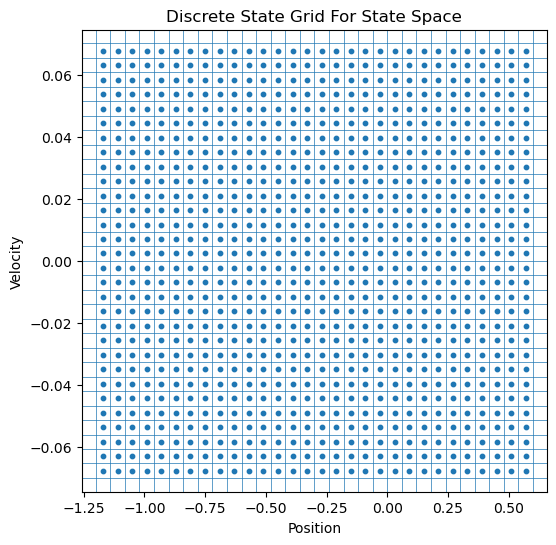

In [2]:
## State Space Visualization


# Defining position and velocity bins
pos_bins = np.linspace(-1.2, 0.6, 31)
vel_bins = np.linspace(-0.07, 0.07, 31)

# Compute grid points (bin centers)
pos_centers = (pos_bins[:-1] + pos_bins[1:]) / 2
vel_centers = (vel_bins[:-1] + vel_bins[1:]) / 2
P, V = np.meshgrid(pos_centers, vel_centers)

# Plot discretization grid
plt.figure(figsize=(6, 6))
plt.scatter(P.flatten(), V.flatten(), s=10)
for pb in pos_bins:
    plt.axvline(pb, linewidth=0.5)
for vb in vel_bins:
    plt.axhline(vb, linewidth=0.5)
plt.title("Discrete State Grid For State Space")
plt.xlabel("Position")
plt.ylabel("Velocity")
plt.show()


In [2]:
## Define Custom Mountain car Env

class CustomMountainCar(gym.Env):
    def __init__(self, render_mode=None):
        super().__init__()
        # Action space
        self.action_space = spaces.Discrete(3)
        # Observation space
        self.observation_space = spaces.Box(
            low=np.array([-1.2, -0.07]), high=np.array([0.6, 0.07]), dtype=np.float32
        )
        # Discretization 
        self.num_bins = 30
        self.pos_bins = np.linspace(-1.2, 0.6, self.num_bins + 1)
        self.vel_bins = np.linspace(-0.07, 0.07, self.num_bins + 1)
        # Constants
        self.F = 0.001
        self.g = 0.0025
        self.max_steps = 200
        self.state = None
        self.step_count = 0
        # Rendering
        self.render_mode = render_mode
        self.viewer_env = gym.make("MountainCar-v0", render_mode=render_mode) if render_mode else None
    
    def discretize_state(self, state):
        pos, vel = state
        pos_idx = np.digitize(pos, self.pos_bins) - 1
        vel_idx = np.digitize(vel, self.vel_bins) - 1
        pos_idx = np.clip(pos_idx, 0, self.num_bins - 1)
        vel_idx = np.clip(vel_idx, 0, self.num_bins - 1)
        return (pos_idx, vel_idx)
    
    def step(self, action):
        assert self.action_space.contains(action), "Invalid action"
        pos, vel = self.state
        self.step_count += 1
        
        # Equations of motion
        vel_next = vel + (action - 1) * self.F - np.cos(3 * pos) * self.g
        pos_next = pos + vel_next
        
        # Boundaries
        if pos_next < -1.2:
            pos_next = -1.2
            vel_next = 0
        elif pos_next > 0.6:
            pos_next = 0.6
            vel_next = 0
        
        self.state = [pos_next, vel_next]
        discrete_state = self.discretize_state(self.state)
        
        # Termination
        terminated = pos_next >= 0.5
        truncated = self.step_count >= self.max_steps
        reward = -1.0 if not terminated else 0.0 ### reward = -1, if not reached at the target
        
        # Render if enabled
        if self.viewer_env:
            self.viewer_env.unwrapped.state = np.array([pos_next, vel_next], dtype=np.float32)
            self.viewer_env.render()
        
        return discrete_state, reward, terminated, truncated, {}
    
    def reset(self, seed=None):
        self.state = [np.random.uniform(-0.6, -0.4), 0.0]
        self.step_count = 0
        if self.viewer_env:
            self.viewer_env.reset(seed=seed)
            self.viewer_env.unwrapped.state = np.array(self.state, dtype=np.float32)
        return self.discretize_state(self.state), {}
    
    def close(self):
        if self.viewer_env:
            self.viewer_env.close()

In [4]:
## Creating Env Instance and test the env

env = CustomMountainCar()
observation, info = env.reset()
episode_over = False
total_reward = 0
positions = [env.state[0]]  

while not episode_over:
    action = env.action_space.sample()  
    observation, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    positions.append(env.state[0])
    episode_over = terminated or truncated

print(f"Episode finished! Total reward: {total_reward}")
env.close()

Episode finished! Total reward: -200.0


/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/gymnasium/spaces/box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


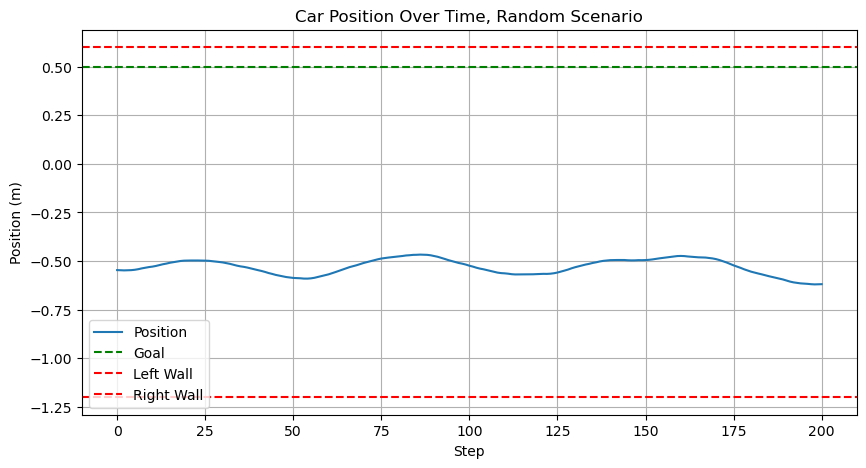

In [5]:
## Plot position for this random movement

plt.figure(figsize=(10, 5))
plt.plot(positions, label='Position')
plt.axhline(y=0.5, color='g', linestyle='--', label='Goal')
plt.axhline(y=-1.2, color='r', linestyle='--', label='Left Wall')
plt.axhline(y=0.6, color='r', linestyle='--', label='Right Wall')
plt.xlabel('Step')
plt.ylabel('Position (m)')
plt.title('Car Position Over Time, Random Scenario')
plt.legend()
plt.grid(True)
plt.show()

### <a id='toc1_2_'></a>[Q-Learning](#toc0_)  

In [6]:
### Q-Learning Params


import time

# Parameters

alpha = 0.1  
gamma = 0.99 
epsilon = 1.0  
epsilon_decay = 0.995  
epsilon_min = 0.1  
n_episodes = 10000  
max_steps = 200

# Q-table init
# Q-table: states (30 x 30) x actions (3)
num_bins = 30
num_actions = 3
Q = np.zeros((num_bins, num_bins, num_actions))

In [7]:
# Cell 3: Q-Learning Training Loop
env = CustomMountainCar()  # No rendering during training for speed

episode_rewards = []
episode_steps = []
successes = []  

start_time = time.time()

for episode in range(n_episodes):
    state, _ = env.reset()
    total_reward = 0
    steps = 0
    done = False
    
    while not done and steps < max_steps:
        # Epsilon-greedy action selection
        if np.random.rand() < epsilon:
            action = env.action_space.sample()  # Explore
        else:
            action = np.argmax(Q[state])  # Exploit
        
        next_state, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        steps += 1
        
        # Q-update
        best_next_action = np.argmax(Q[next_state])
        Q[state][action] += alpha * (reward + gamma * Q[next_state][best_next_action] - Q[state][action])
        
        state = next_state
        done = terminated or truncated
    
    # Track metrics
    episode_rewards.append(total_reward)
    episode_steps.append(steps)
    successes.append(1 if terminated else 0)
    
    # Decay epsilon
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

training_time = time.time() - start_time
env.close()

In [8]:
## Evaluations and Metrics
# Average reward over last 100 episodes
avg_reward_last_100 = np.mean(episode_rewards[-100:])

# Success rate over last 100 episodes
success_rate_last_100 = np.mean(successes[-100:]) * 100

# Average steps to success (use max_steps if failed)
avg_steps_last_100 = np.mean([
    s if succ else max_steps for s, succ in zip(episode_steps[-100:], successes[-100:])
])

print(f"Training time: {training_time:.2f} seconds")
print(f"Average reward (last 100 episodes): {avg_reward_last_100:.2f}")
print(f"Success rate (last 100 episodes): {success_rate_last_100:.2f}%")
print(f"Average steps (last 100 episodes, max if fail): {avg_steps_last_100:.2f}")

Training time: 92.43 seconds
Average reward (last 100 episodes): -148.82
Success rate (last 100 episodes): 100.00%
Average steps (last 100 episodes, max if fail): 149.82


/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


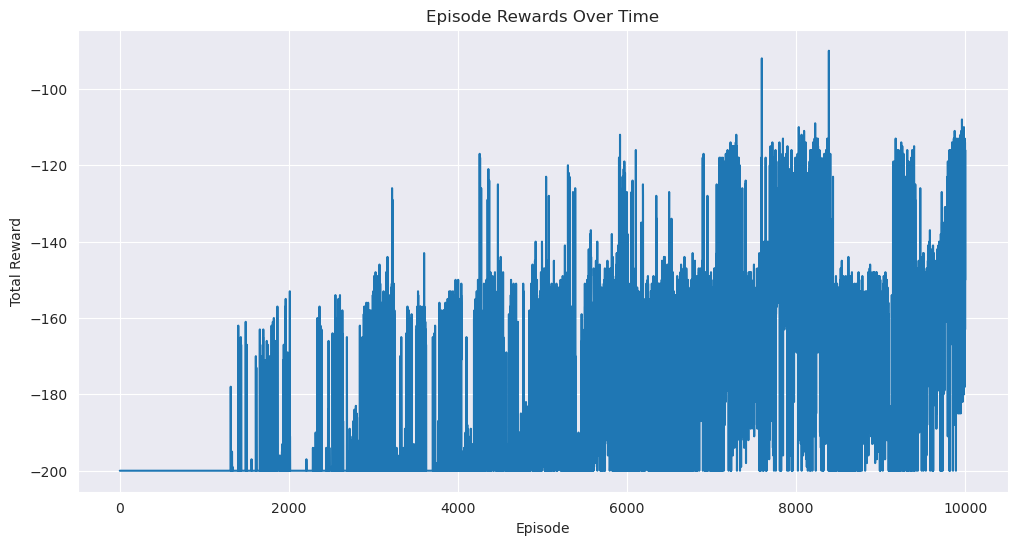

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


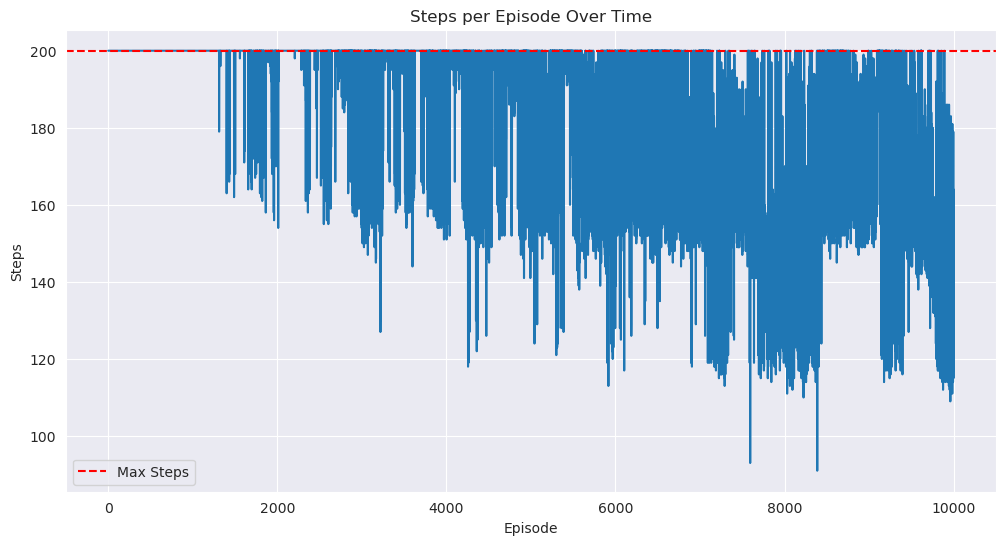

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


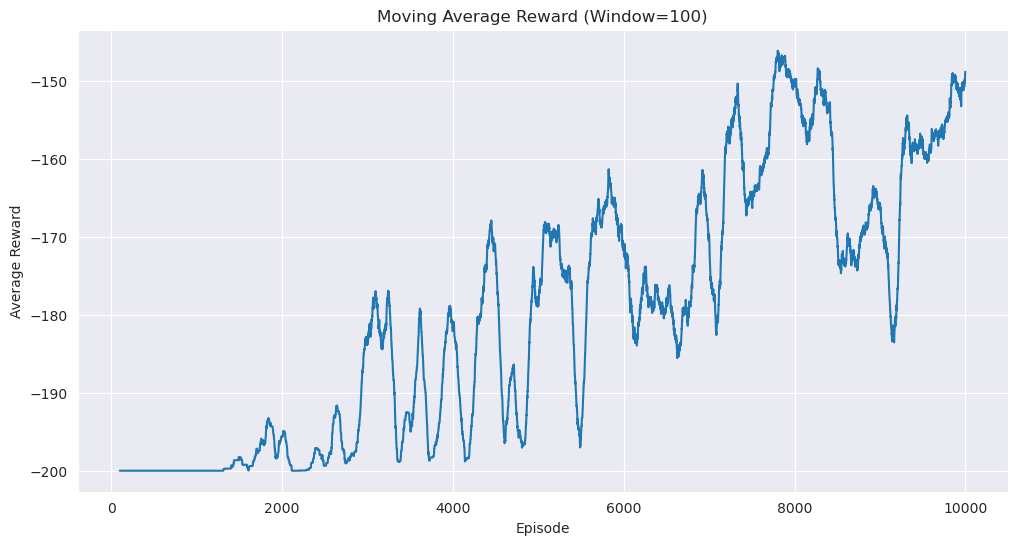

In [9]:
## Plots with Seaborn
sns.set_style(style="darkgrid")

# Plot episode rewards
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_rewards)
plt.title('Episode Rewards Over Time')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.show()

# Plot steps per episode
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_steps)
plt.title('Steps per Episode Over Time')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.axhline(y=200, color='r', linestyle='--', label='Max Steps')
plt.legend()
plt.show()

# Moving average reward for smoother trend
window_size = 100
moving_avg_rewards = np.convolve(episode_rewards, np.ones(window_size)/window_size, mode='valid')
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(window_size-1, n_episodes), y=moving_avg_rewards)
plt.title('Moving Average Reward (Window=100)')
plt.xlabel('Episode')
plt.ylabel('Average Reward')
plt.show()

In [10]:
### Render Animation and Save as GIF


import imageio.v3 as iio


# Initialize environment with rgb_array rendering for GIF
env_test = CustomMountainCar(render_mode="rgb_array")
state, _ = env_test.reset()
done = False
steps = 0
frames = []  
positions = [env_test.state[0]]
velocities = [env_test.state[1]]

while not done and steps < max_steps:
    action = np.argmax(Q[state]) 
    next_state, reward, terminated, truncated, _ = env_test.step(action)
    steps += 1
    positions.append(env_test.state[0])
    velocities.append(env_test.state[1])
    
    frame = env_test.viewer_env.render()
    frames.append(frame)
    
    state = next_state
    done = terminated or truncated

# Save frames as GIF
iio.imwrite(
    'mountain_car_test.gif',
    frames,
    duration=40,  
    loop=0  
)

env_test.close()

reached_flag = terminated
print(f"Test episode: Reached flag: {reached_flag}, Steps taken: {steps}")



/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/gymnasium/spaces/box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


Test episode: Reached flag: True, Steps taken: 174


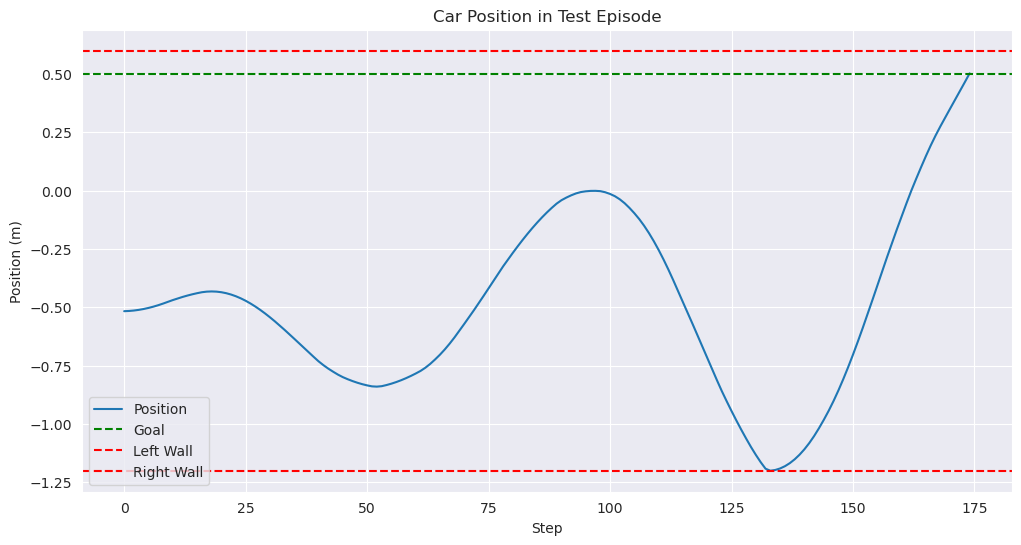

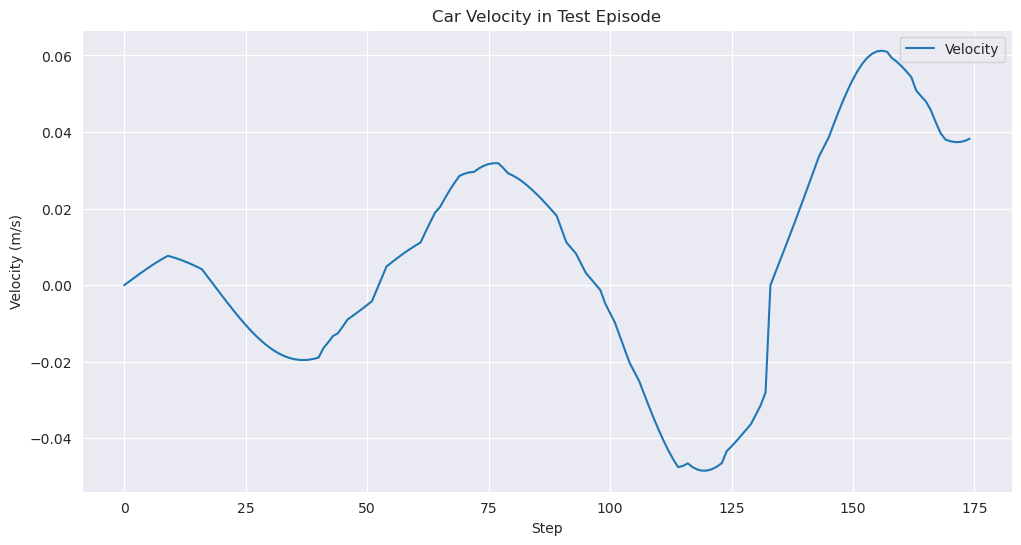

In [11]:
# Plot test trajectory 

plt.figure(figsize=(12, 6))
plt.plot(positions, label='Position')
plt.axhline(y=0.5, color='g', linestyle='--', label='Goal')
plt.axhline(y=-1.2, color='r', linestyle='--', label='Left Wall')
plt.axhline(y=0.6, color='r', linestyle='--', label='Right Wall')
plt.title('Car Position in Test Episode')
plt.xlabel('Step')
plt.ylabel('Position (m)')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(velocities, label='Velocity')
plt.title('Car Velocity in Test Episode')
plt.xlabel('Step')
plt.ylabel('Velocity (m/s)')
plt.legend()
plt.grid(True)
plt.show()



---

### <a id='toc1_3_'></a>[Double Q-Learning](#toc0_)  

In [12]:
## Double Q-Learning Parameters (Its same as before)
alpha = 0.1  
gamma = 0.99  
epsilon = 1.0  
epsilon_decay = 0.995  
epsilon_min = 0.1  
n_episodes = 10000  
max_steps = 200  

# Two Q-tables instead of just one
num_bins = 30
num_actions = 3
Q1 = np.zeros((num_bins, num_bins, num_actions))
Q2 = np.zeros((num_bins, num_bins, num_actions))

In [13]:
## Double Q-Learning Training Loop
env = CustomMountainCar()  # No rendering during training for speed

episode_rewards = []
episode_steps = []
successes = []

start_time = time.time()

for episode in range(n_episodes):
    state, _ = env.reset()
    total_reward = 0
    steps = 0
    done = False
    
    while not done and steps < max_steps:
        # Epsilon-greedy action selection (use average of Q1 and Q2)
        if np.random.rand() < epsilon:
            action = env.action_space.sample()  # Explore
        else:
            Q_avg = (Q1[state] + Q2[state]) / 2
            action = np.argmax(Q_avg)  # Exploit
        
        next_state, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        steps += 1
        
        # Update one Q-table randomly
        if np.random.rand() < 0.5:
            # Update Q1 using Q2
            best_next_action = np.argmax(Q1[next_state])
            Q1[state][action] += alpha * (
                reward + gamma * Q2[next_state][best_next_action] - Q1[state][action]
            )
        else:
            # Update Q2 using Q1
            best_next_action = np.argmax(Q2[next_state])
            Q2[state][action] += alpha * (
                reward + gamma * Q1[next_state][best_next_action] - Q2[state][action]
            )
        
        state = next_state
        done = terminated or truncated
    
    episode_rewards.append(total_reward)
    episode_steps.append(steps)
    successes.append(1 if terminated else 0)
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

training_time = time.time() - start_time
env.close()

In [14]:
##Evaluations and Metrics

avg_reward_last_100 = np.mean(episode_rewards[-100:])
success_rate_last_100 = np.mean(successes[-100:]) * 100
avg_steps_last_100 = np.mean([
    s if succ else max_steps for s, succ in zip(episode_steps[-100:], successes[-100:])
])

print(f"Training time: {training_time:.2f} seconds")
print(f"Average reward (last 100 episodes): {avg_reward_last_100:.2f}")
print(f"Success rate (last 100 episodes): {success_rate_last_100:.2f}%")
print(f"Average steps (last 100 episodes, max if fail): {avg_steps_last_100:.2f}")

Training time: 124.15 seconds
Average reward (last 100 episodes): -173.57
Success rate (last 100 episodes): 58.00%
Average steps (last 100 episodes, max if fail): 174.15


/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


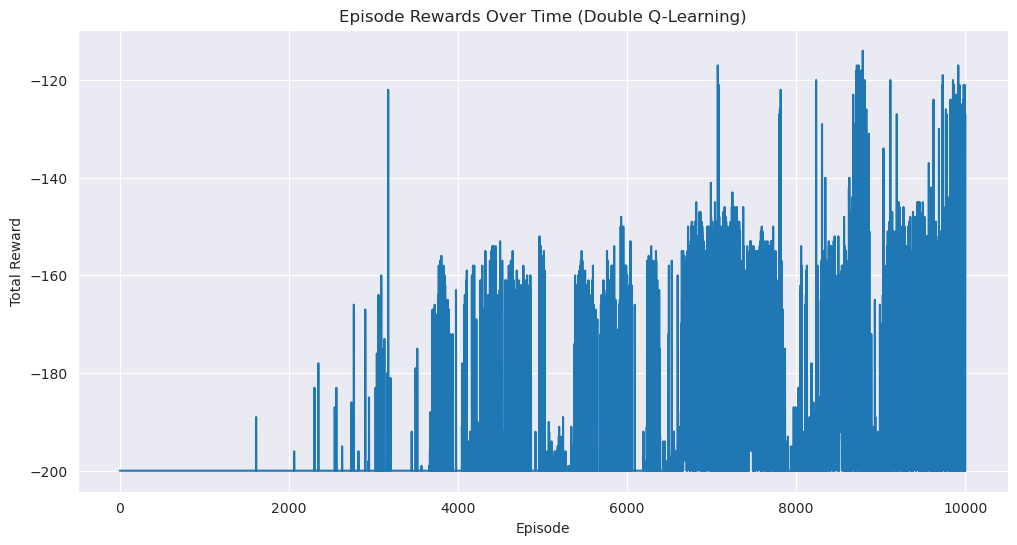

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


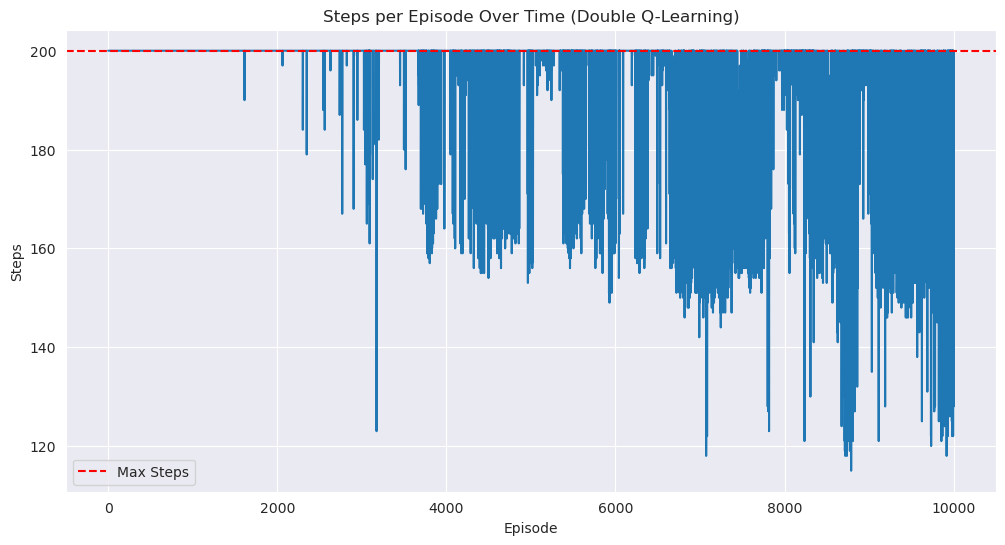

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


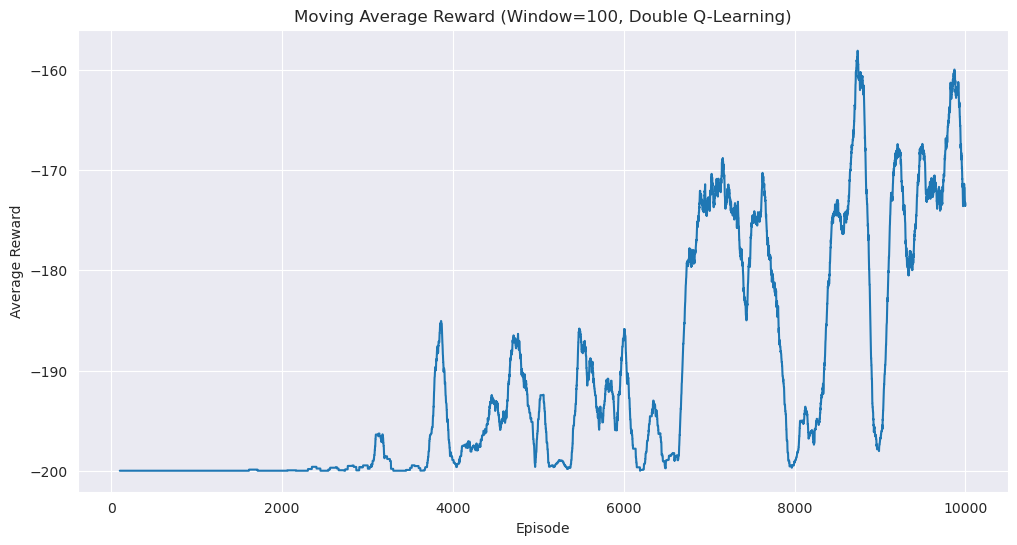

In [15]:
# Cell 5: Plots with Seaborn
sns.set_style(style="darkgrid")

# Episode rewards
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_rewards)
plt.title('Episode Rewards Over Time (Double Q-Learning)')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.show()

# Steps per episode
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_steps)
plt.title('Steps per Episode Over Time (Double Q-Learning)')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.axhline(y=200, color='r', linestyle='--', label='Max Steps')
plt.legend()
plt.show()

# Moving average reward
window_size = 100
moving_avg_rewards = np.convolve(episode_rewards, np.ones(window_size)/window_size, mode='valid')
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(window_size-1, n_episodes), y=moving_avg_rewards)
plt.title('Moving Average Reward (Window=100, Double Q-Learning)')
plt.xlabel('Episode')
plt.ylabel('Average Reward')
plt.show()

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/gymnasium/spaces/box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


Test episode: Reached flag: True, Steps taken: 157


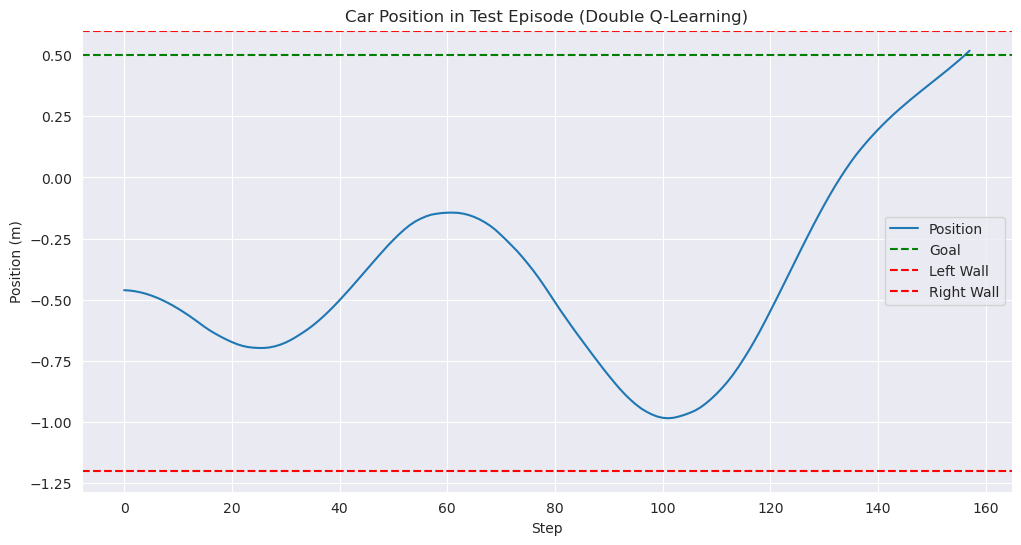

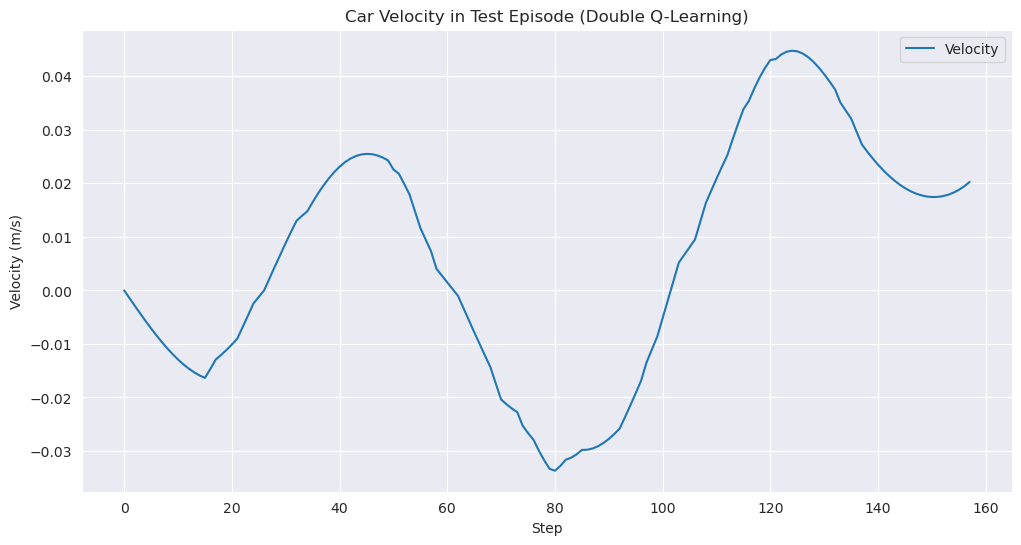

In [16]:
## Test the Trained Model with Rendering and Save as GIF

env_test = CustomMountainCar(render_mode="rgb_array")
state, _ = env_test.reset()
done = False
steps = 0
frames = []
positions = [env_test.state[0]]
velocities = [env_test.state[1]]

while not done and steps < max_steps:
    Q_avg = (Q1[state] + Q2[state]) / 2
    action = np.argmax(Q_avg)  # Greedy action
    next_state, reward, terminated, truncated, _ = env_test.step(action)
    steps += 1
    positions.append(env_test.state[0])
    velocities.append(env_test.state[1])
    frame = env_test.viewer_env.render()
    frames.append(frame)
    state = next_state
    done = terminated or truncated

iio.imwrite(
    'mountain_car_double_q_test.gif',
    frames,
    duration=40,
    loop=0
)

env_test.close()

reached_flag = terminated
print(f"Test episode: Reached flag: {reached_flag}, Steps taken: {steps}")

plt.figure(figsize=(12, 6))
plt.plot(positions, label='Position')
plt.axhline(y=0.5, color='g', linestyle='--', label='Goal')
plt.axhline(y=-1.2, color='r', linestyle='--', label='Left Wall')
plt.axhline(y=0.6, color='r', linestyle='--', label='Right Wall')
plt.title('Car Position in Test Episode (Double Q-Learning)')
plt.xlabel('Step')
plt.ylabel('Position (m)')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(velocities, label='Velocity')
plt.title('Car Velocity in Test Episode (Double Q-Learning)')
plt.xlabel('Step')
plt.ylabel('Velocity (m/s)')
plt.legend()
plt.grid(True)
plt.show()



---

### <a id='toc1_4_'></a>[Deep Q-Learning](#toc0_)  

In [3]:
## Importing torch as nn Framework
import torch
import torch.nn as nn
import torch.optim as optim
import random
from collections import deque

# DQN Model Architecture, simple for this problem
class DQN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(DQN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, output_dim)
        )
    
    def forward(self, x):
        return self.net(x)

# Parameters
alpha = 0.1  
gamma = 0.99 
epsilon = 1.0 
epsilon_decay = 0.995
epsilon_min = 0.01
n_episodes = 500 ## Different
max_steps = 200
batch_size = 64
memory_capacity = 10000
target_update = 10  

# Initialize
env = CustomMountainCar()
input_dim = 2  # Position, velocity
output_dim = 3  # Actions
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
q_network = DQN(input_dim, output_dim).to(device)
target_network = DQN(input_dim, output_dim).to(device)
target_network.load_state_dict(q_network.state_dict())
optimizer = optim.Adam(q_network.parameters(), lr=0.001)
criterion = nn.MSELoss()
memory = deque(maxlen=memory_capacity)

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/gymnasium/spaces/box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


In [18]:
## DQN Training Loop
episode_rewards = []
episode_steps = []
successes = []

start_time = time.time()

for episode in range(n_episodes):
    state, _ = env.reset()
    total_reward = 0
    steps = 0
    done = False
    
    while not done and steps < max_steps:
        state_tensor = torch.FloatTensor(state).to(device)
        # Epsilon-greedy
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                q_values = q_network(state_tensor)
                action = q_values.argmax().item()
        
        next_state, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        steps += 1
        
        # Store experience
        memory.append((state, action, reward, next_state, terminated))
        state = next_state
        done = terminated or truncated
        
        
        if len(memory) >= batch_size:
            batch = random.sample(memory, batch_size)
            states, actions, rewards, next_states, dones = zip(*batch)
            
            states = torch.FloatTensor(states).to(device)
            actions = torch.LongTensor(actions).to(device)
            rewards = torch.FloatTensor(rewards).to(device)
            next_states = torch.FloatTensor(next_states).to(device)
            dones = torch.FloatTensor(dones).to(device)
            
           
            q_values = q_network(states).gather(1, actions.unsqueeze(1)).squeeze(1)
            with torch.no_grad():
                next_q_values = target_network(next_states).max(1)[0]
                targets = rewards + gamma * next_q_values * (1 - dones)
            
           
            loss = criterion(q_values, targets)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    
    episode_rewards.append(total_reward)
    episode_steps.append(steps)
    successes.append(1 if terminated else 0)
    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    
    # Update target network
    if (episode + 1) % target_update == 0:
        target_network.load_state_dict(q_network.state_dict())

training_time = time.time() - start_time
env.close()

/tmp/ipykernel_9738/3307439562.py:42: DeprecationWarning: In future, it will be an error for 'np.bool_' scalars to be interpreted as an index
  dones = torch.FloatTensor(dones).to(device)


In [19]:
## Evaluations and Metrics
avg_reward_last_100 = np.mean(episode_rewards[-100:])
success_rate_last_100 = np.mean(successes[-100:]) * 100
avg_steps_last_100 = np.mean([
    s if succ else max_steps for s, succ in zip(episode_steps[-100:], successes[-100:])
])

print(f"Training time: {training_time:.2f} seconds")
print(f"Average reward (last 100 episodes): {avg_reward_last_100:.2f}")
print(f"Success rate (last 100 episodes): {success_rate_last_100:.2f}%")
print(f"Average steps (last 100 episodes, max if fail): {avg_steps_last_100:.2f}")

Training time: 290.56 seconds
Average reward (last 100 episodes): -176.89
Success rate (last 100 episodes): 59.00%
Average steps (last 100 episodes, max if fail): 177.48


/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


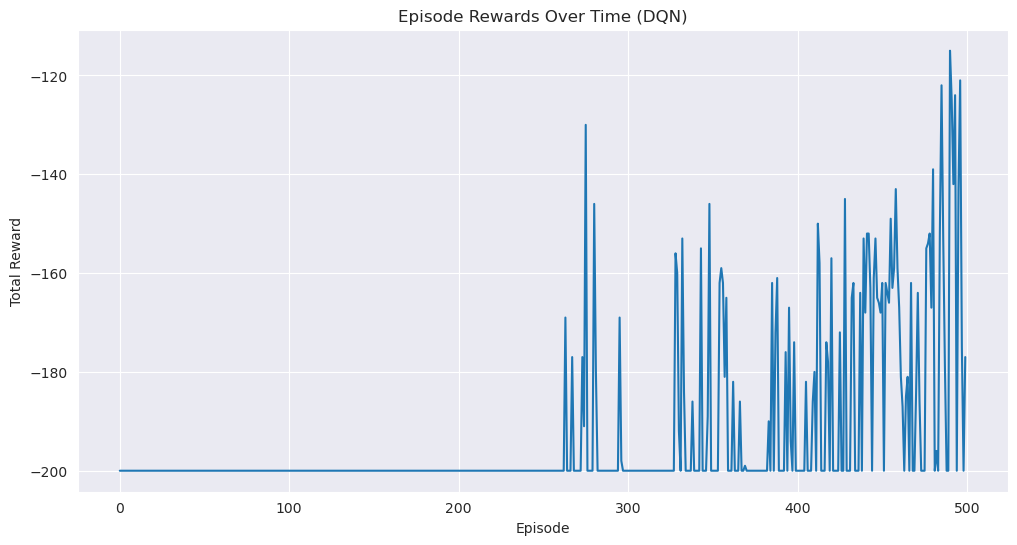

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


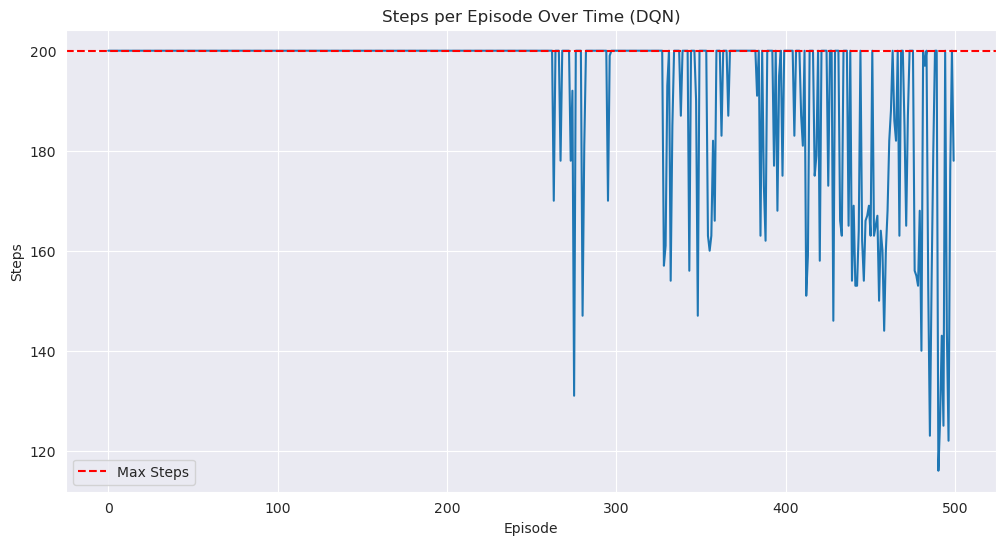

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


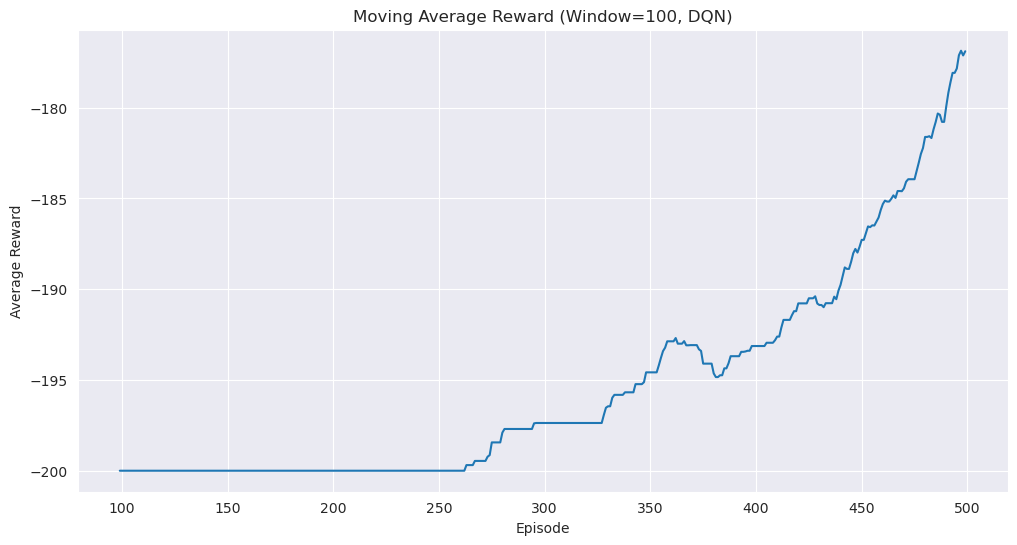

In [20]:
##Plots with Seaborn

# Episode rewards
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_rewards)
plt.title('Episode Rewards Over Time (DQN)')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.show()

# Steps per episode
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_steps)
plt.title('Steps per Episode Over Time (DQN)')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.axhline(y=200, color='r', linestyle='--', label='Max Steps')
plt.legend()
plt.show()

# Moving average reward
window_size = 100
moving_avg_rewards = np.convolve(episode_rewards, np.ones(window_size)/window_size, mode='valid')
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(window_size-1, n_episodes), y=moving_avg_rewards)
plt.title('Moving Average Reward (Window=100, DQN)')
plt.xlabel('Episode')
plt.ylabel('Average Reward')
plt.show()

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/gymnasium/spaces/box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


Test episode: Reached flag: False, Steps taken: 200


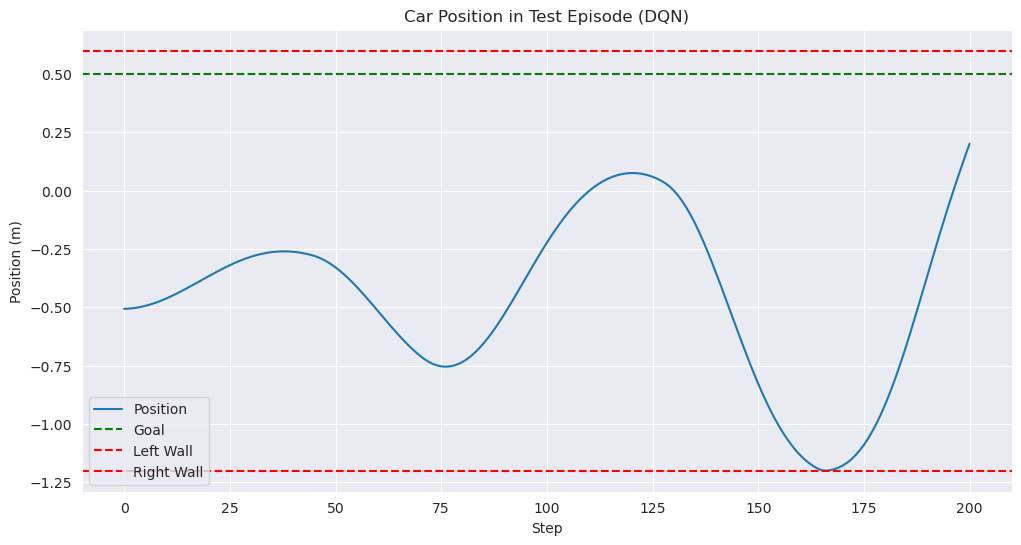

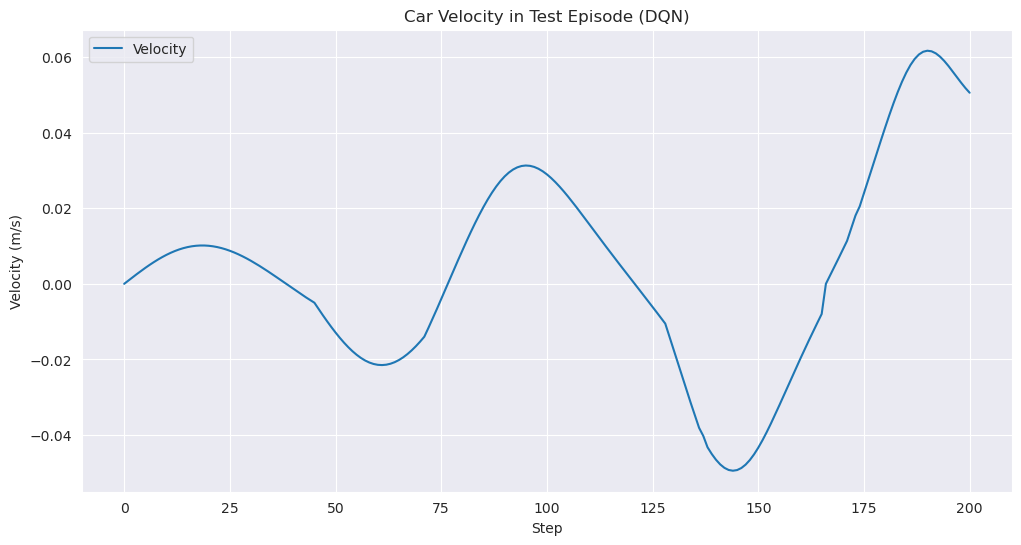

In [21]:
## Test the Trained Model with Rendering and Save as GIF

env_test = CustomMountainCar(render_mode="rgb_array")
state, _ = env_test.reset()
done = False
steps = 0
frames = []
positions = [env_test.state[0]]
velocities = [env_test.state[1]]

while not done and steps < max_steps:
    state_tensor = torch.FloatTensor(state).to(device)
    with torch.no_grad():
        q_values = q_network(state_tensor)
        action = q_values.argmax().item()
    next_state, reward, terminated, truncated, _ = env_test.step(action)
    steps += 1
    positions.append(env_test.state[0])
    velocities.append(env_test.state[1])
    frame = env_test.viewer_env.render()
    frames.append(frame)
    state = next_state
    done = terminated or truncated

iio.imwrite(
    'mountain_car_dqn_test.gif',
    frames,
    duration=40,
    loop=0
)

env_test.close()

reached_flag = terminated
print(f"Test episode: Reached flag: {reached_flag}, Steps taken: {steps}")

plt.figure(figsize=(12, 6))
plt.plot(positions, label='Position')
plt.axhline(y=0.5, color='g', linestyle='--', label='Goal')
plt.axhline(y=-1.2, color='r', linestyle='--', label='Left Wall')
plt.axhline(y=0.6, color='r', linestyle='--', label='Right Wall')
plt.title('Car Position in Test Episode (DQN)')
plt.xlabel('Step')
plt.ylabel('Position (m)')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(velocities, label='Velocity')
plt.title('Car Velocity in Test Episode (DQN)')
plt.xlabel('Step')
plt.ylabel('Velocity (m/s)')
plt.legend()
plt.grid(True)
plt.show()



___
___

## <a id='toc2_'></a>[Continues Environment](#toc0_)  

### <a id='toc2_1_'></a>[Preparing the Custom Environment](#toc0_)  

In [2]:

## Continuous MountainCar environment

class CustomMountainCarContinuous(gym.Env):
    def __init__(self, render_mode=None):
        super().__init__()
        # Action space: continuous force in [-1, 1]
        self.action_space = spaces.Box(low=-1.0, high=1.0, shape=(1,), dtype=np.float32)
        # Observation space: position [-1.2, 0.6], velocity [-0.07, 0.07], but not discrete
        self.observation_space = spaces.Box(
            low=np.array([-1.2, -0.07]), high=np.array([0.6, 0.07]), dtype=np.float32
        )
        # Constants
        self.force_multiplier = 0.0015
        self.gravity = 0.0025
        self.max_steps = 200
        self.state = None
        self.step_count = 0
        # For visualization using Gym's renderer
        self.render_mode = render_mode
        self.viewer_env = gym.make("MountainCarContinuous-v0", render_mode=render_mode) if render_mode else None
    
    def step(self, action):
        assert self.action_space.contains(action), "Invalid action"
        action = action[0]  # Extract scalar force F
        pos, vel = self.state
        self.step_count += 1
        
        # Equations of motion
        vel_next = vel + action * self.force_multiplier - np.cos(3 * pos) * self.gravity
        pos_next = pos + vel_next
        
        # Boundary conditions (walls)
        if pos_next < -1.2:
            pos_next = -1.2
            vel_next = 0
        elif pos_next > 0.6:
            pos_next = 0.6
            vel_next = 0
        
        self.state = [pos_next, vel_next]
        
        # Termination conditions
        terminated = pos_next >= 0.5
        truncated = self.step_count >= self.max_steps
        reward = -1.0 if not terminated else 0.0  # Standard reward
        
        # Render if enabled
        if self.viewer_env:
            self.viewer_env.unwrapped.state = np.array([pos_next, vel_next], dtype=np.float32)
            self.viewer_env.render()
        
        return np.array(self.state, dtype=np.float32), reward, terminated, truncated, {}
    
    def reset(self, seed=None):
        # Initial state: position random in [-0.6, -0.4], velocity=0
        self.state = [np.random.uniform(-0.6, -0.4), 0.0] ## Uniform Distribution
        self.step_count = 0
        if self.viewer_env:
            self.viewer_env.reset(seed=seed)
            self.viewer_env.unwrapped.state = np.array(self.state, dtype=np.float32)
        return np.array(self.state, dtype=np.float32), {}
    
    def close(self):
        if self.viewer_env:
            self.viewer_env.close()

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/gymnasium/spaces/box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


Episode finished! Total reward: -200.0


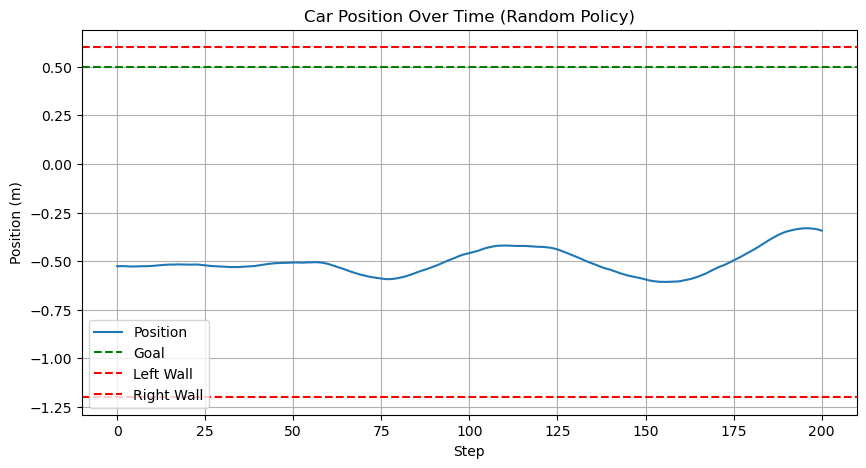

In [3]:
# Cell 2: Test the Continuous Environment
env = CustomMountainCarContinuous(render_mode="human")
observation, info = env.reset()
episode_over = False
total_reward = 0
positions = [env.state[0]]  # For plotting

while not episode_over:
    action = env.action_space.sample()  # Random continuous action [-1, 1]
    observation, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    positions.append(env.state[0])
    episode_over = terminated or truncated

print(f"Episode finished! Total reward: {total_reward}")
env.close()

# Cell 3: Plot Position Over Time
plt.figure(figsize=(10, 5))
plt.plot(positions, label='Position')
plt.axhline(y=0.5, color='g', linestyle='--', label='Goal')
plt.axhline(y=-1.2, color='r', linestyle='--', label='Left Wall')
plt.axhline(y=0.6, color='r', linestyle='--', label='Right Wall')
plt.xlabel('Step')
plt.ylabel('Position (m)')
plt.title('Car Position Over Time (Random Policy)')
plt.legend()
plt.grid(True)
plt.show()

____

### <a id='toc2_2_'></a>[DQN](#toc0_)  

In [3]:
## DQN Setup with State Normalization
import torch
import torch.nn as nn
import torch.optim as optim
import random
import seaborn as sns
import time
from collections import deque

class DQN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(DQN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, output_dim)
        )
    
    def forward(self, x):
        return self.net(x)

# Parameters
gamma = 0.99
epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.01
n_episodes = 500
max_steps = 200
batch_size = 64
memory_capacity = 10000
target_update = 10

# Action discretization
num_actions = 10
discrete_actions = np.linspace(-1.0, 1.0, num_actions)

# State normalization parameters --> THIS IS NEEDED IN ORDER FOR THE MODEL TO TRAIN PROPERLY.
state_mean = np.array([(-1.2 + 0.6) / 2, 0.0])  
state_scale = np.array([(0.6 - (-1.2)) / 2, 0.07]) 

# Initialize
env = CustomMountainCarContinuous()
input_dim = 2
output_dim = num_actions
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
q_network = DQN(input_dim, output_dim).to(device)
target_network = DQN(input_dim, output_dim).to(device)
target_network.load_state_dict(q_network.state_dict())
optimizer = optim.Adam(q_network.parameters(), lr=0.001)
criterion = nn.MSELoss()
memory = deque(maxlen=memory_capacity)

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/gymnasium/spaces/box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


In [ ]:
## DQN Training Loop with Debugging to see where the problem is 
episode_rewards = []
episode_steps = []
successes = []

start_time = time.time()

for episode in range(n_episodes):
    state, _ = env.reset()
    total_reward = 0
    steps = 0
    done = False
    
    while not done and steps < max_steps:
        # Normalize state
        norm_state = (state - state_mean) / state_scale
        state_tensor = torch.FloatTensor(norm_state).to(device)
        
        # Epsilon-greedy
        if random.random() < epsilon:
            action_idx = random.randint(0, num_actions - 1)
        else:
            with torch.no_grad():
                q_values = q_network(state_tensor)
                action_idx = q_values.argmax().item()
        
        action = np.array([discrete_actions[action_idx]], dtype=np.float32)
        
        next_state, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        steps += 1
        
        # Store normalized state
        norm_next_state = (next_state - state_mean) / state_scale
        memory.append((norm_state, action_idx, reward, norm_next_state, terminated))
        state = next_state
        done = terminated or truncated
        
        if len(memory) >= batch_size:
            batch = random.sample(memory, batch_size)
            states, actions, rewards, next_states, dones = zip(*batch)
            
            states = torch.FloatTensor(states).to(device)
            actions = torch.LongTensor(actions).to(device)
            rewards = torch.FloatTensor(rewards).to(device)
            next_states = torch.FloatTensor(next_states).to(device)
            dones = torch.FloatTensor(dones).to(device)
            
            q_values = q_network(states).gather(1, actions.unsqueeze(1)).squeeze(1)
            with torch.no_grad():
                next_q_values = target_network(next_states).max(1)[0]
                targets = rewards + gamma * next_q_values * (1 - dones)
            
            loss = criterion(q_values, targets)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    
    episode_rewards.append(total_reward)
    episode_steps.append(steps)
    successes.append(1 if terminated else 0)
    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    
    if (episode + 1) % target_update == 0:
        target_network.load_state_dict(q_network.state_dict())
    
    # Debugging every 100 episodes
    if (episode + 1) % 100 == 0:
        print(f"Episode {episode + 1}: Reward={total_reward:.2f}, Steps={steps}, Epsilon={epsilon:.3f}")

training_time = time.time() - start_time
env.close()

/tmp/ipykernel_6415/4060037504.py:47: DeprecationWarning: In future, it will be an error for 'np.bool_' scalars to be interpreted as an index
  dones = torch.FloatTensor(dones).to(device)


Episode 100: Reward=-200.00, Steps=200, Epsilon=0.606
Episode 200: Reward=-200.00, Steps=200, Epsilon=0.367
Episode 300: Reward=-200.00, Steps=200, Epsilon=0.222
Episode 400: Reward=-200.00, Steps=200, Epsilon=0.135
Episode 500: Reward=-124.00, Steps=125, Epsilon=0.082


In [ ]:
## Evaluations and Metrics
avg_reward_last_100 = np.mean(episode_rewards[-100:])
success_rate_last_100 = np.mean(successes[-100:]) * 100
avg_steps_last_100 = np.mean([
    s if succ else max_steps for s, succ in zip(episode_steps[-100:], successes[-100:])
])

print(f"Training time: {training_time:.2f} seconds")
print(f"Average reward (last 100 episodes): {avg_reward_last_100:.2f}")
print(f"Success rate (last 100 episodes): {success_rate_last_100:.2f}%")
print(f"Average steps (last 100 episodes, max if fail): {avg_steps_last_100:.2f}")

Training time: 141.73 seconds
Average reward (last 100 episodes): -145.46
Success rate (last 100 episodes): 85.00%
Average steps (last 100 episodes, max if fail): 146.31


/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


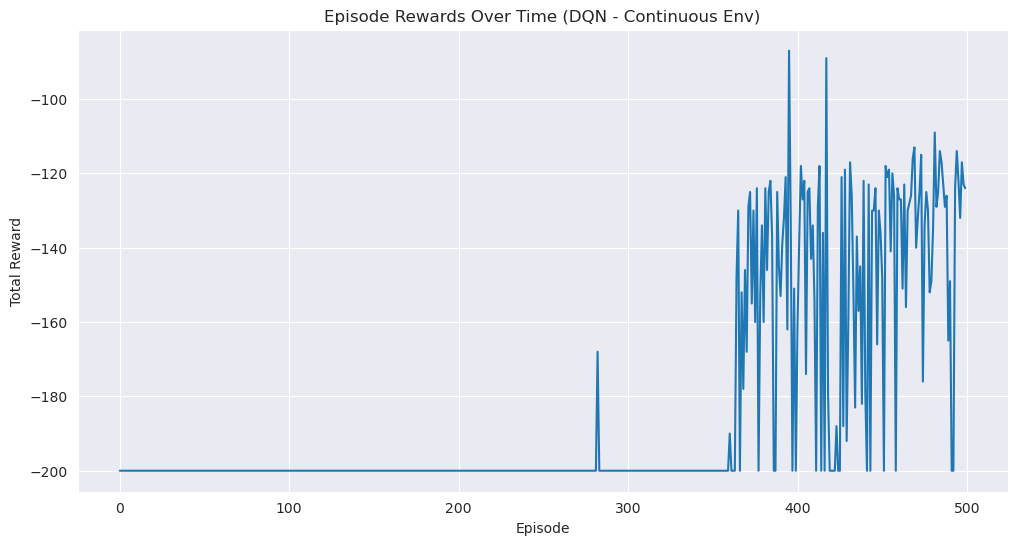

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


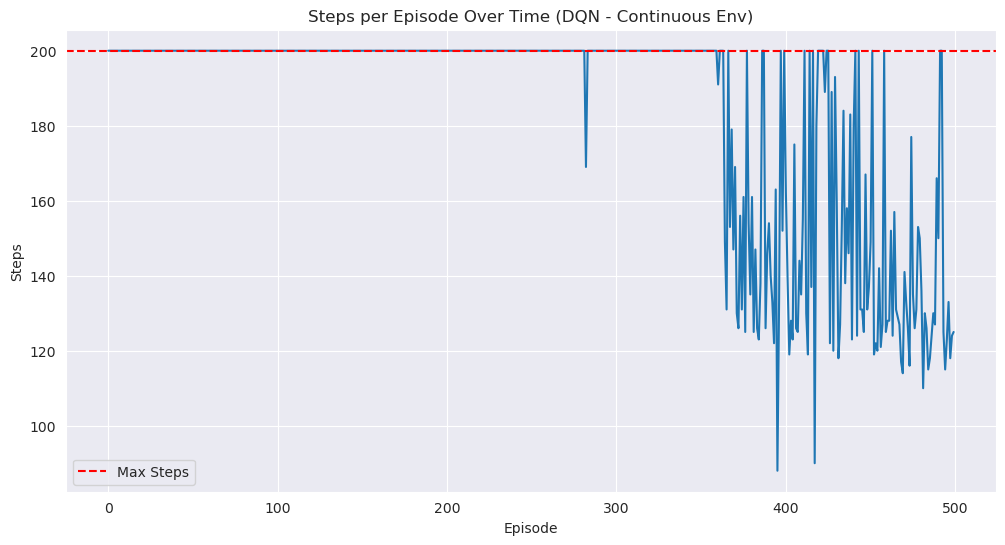

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


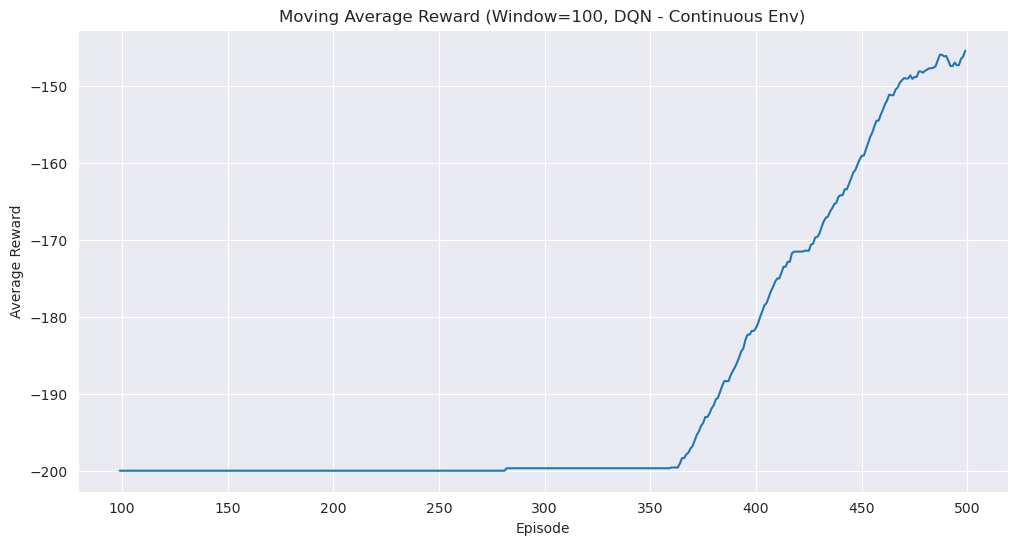

In [ ]:
## Plots with Seaborn
sns.set_style(style="darkgrid")

plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_rewards)
plt.title('Episode Rewards Over Time (DQN - Continuous Env)')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.show()

plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_steps)
plt.title('Steps per Episode Over Time (DQN - Continuous Env)')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.axhline(y=200, color='r', linestyle='--', label='Max Steps')
plt.legend()
plt.show()

window_size = 100
moving_avg_rewards = np.convolve(episode_rewards, np.ones(window_size)/window_size, mode='valid')
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(window_size-1, n_episodes), y=moving_avg_rewards)
plt.title('Moving Average Reward (Window=100, DQN - Continuous Env)')
plt.xlabel('Episode')
plt.ylabel('Average Reward')
plt.show()

GIF saved successfully as 'mountain_car_continuous_dqn_test.gif'
Test episode: Reached flag: True, Steps taken: 126


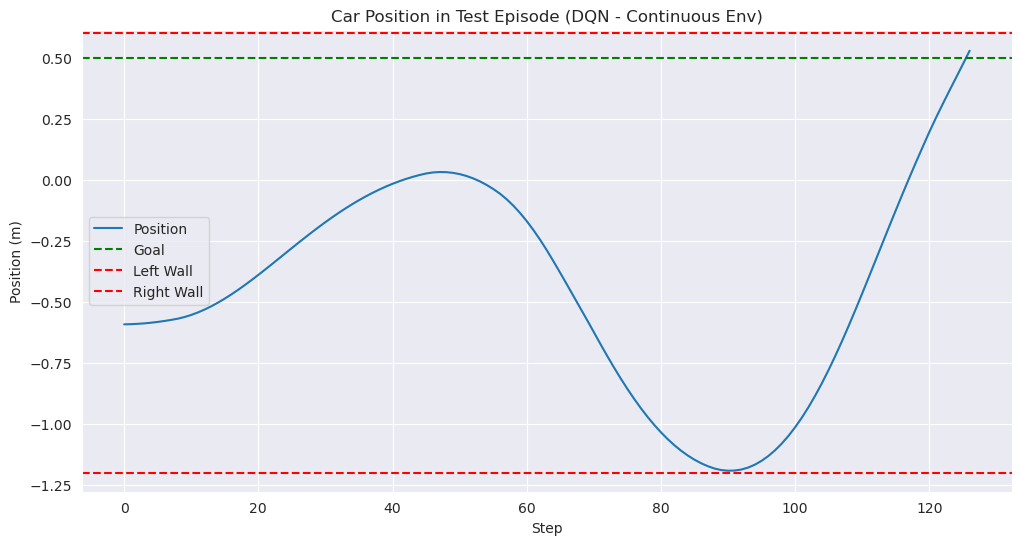

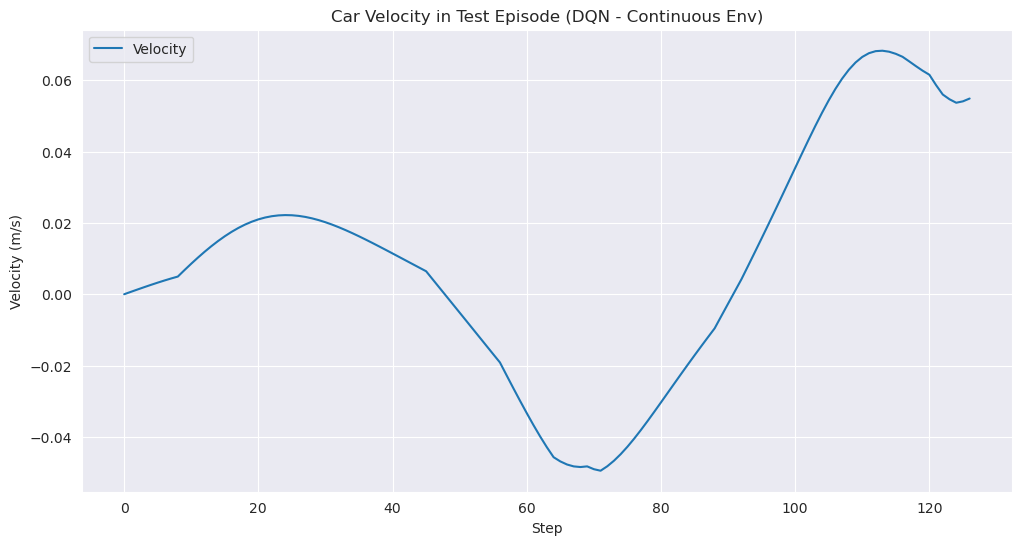

In [ ]:
## Render GIF

env_test = CustomMountainCarContinuous(render_mode="rgb_array")
state, _ = env_test.reset()
done = False
steps = 0
frames = []
positions = [env_test.state[0]]
velocities = [env_test.state[1]]

while not done and steps < max_steps:
    norm_state = (state - state_mean) / state_scale
    state_tensor = torch.FloatTensor(norm_state).to(device)
    with torch.no_grad():
        q_values = q_network(state_tensor)
        action_idx = q_values.argmax().item()
    action = np.array([discrete_actions[action_idx]], dtype=np.float32)
    next_state, reward, terminated, truncated, _ = env_test.step(action)
    steps += 1
    positions.append(env_test.state[0])
    velocities.append(env_test.state[1])
    frame = env_test.viewer_env.render()
    if frame is not None:  # Ensure frame is valid
        frames.append(frame)
    state = next_state
    done = terminated or truncated

# Save GIF
try:
    iio.imwrite(
        'mountain_car_continuous_dqn_test.gif',
        frames,
        duration=40,  # milliseconds per frame
        loop=0
    )
    print("GIF saved successfully as 'mountain_car_continuous_dqn_test.gif'")
except Exception as e:
    print(f"Error saving GIF: {e}")

env_test.close()

reached_flag = terminated
print(f"Test episode: Reached flag: {reached_flag}, Steps taken: {steps}")

# Plot trajectories
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(positions, label='Position')
plt.axhline(y=0.5, color='g', linestyle='--', label='Goal')
plt.axhline(y=-1.2, color='r', linestyle='--', label='Left Wall')
plt.axhline(y=0.6, color='r', linestyle='--', label='Right Wall')
plt.title('Car Position in Test Episode (DQN - Continuous Env)')
plt.xlabel('Step')
plt.ylabel('Position (m)')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(velocities, label='Velocity')
plt.title('Car Velocity in Test Episode (DQN - Continuous Env)')
plt.xlabel('Step')
plt.ylabel('Velocity (m/s)')
plt.legend()
plt.grid(True)
plt.show()



____

### <a id='toc2_3_'></a>[DDPG](#toc0_)  

In [ ]:
## Again we introduce Custom Env (For Runtime purposes)

class CustomMountainCarContinuous(gym.Env):
    def __init__(self, render_mode=None):
        super().__init__()
        self.action_space = spaces.Box(low=-1.0, high=1.0, shape=(1,), dtype=np.float32)
        self.observation_space = spaces.Box(
            low=np.array([-1.2, -0.07]), high=np.array([0.6, 0.07]), dtype=np.float32
        )
        self.force_multiplier = 0.0015
        self.gravity = 0.0025
        self.max_steps = 200
        self.state = None
        self.step_count = 0
        self.render_mode = render_mode
        self.viewer_env = gym.make("MountainCarContinuous-v0", render_mode=render_mode) if render_mode else None
    
    def step(self, action):
        assert self.action_space.contains(action), f"Invalid action: {action}"
        action = np.clip(action[0], -1.0, 1.0)
        pos, vel = self.state
        self.step_count += 1
        
        vel_next = vel + action * self.force_multiplier - np.cos(3 * pos) * self.gravity
        pos_next = pos + vel_next
        
        if pos_next < -1.2:
            pos_next = -1.2
            vel_next = 0
        elif pos_next > 0.6:
            pos_next = 0.6
            vel_next = 0
        
        self.state = [pos_next, vel_next]
        
        terminated = pos_next >= 0.5
        truncated = self.step_count >= self.max_steps
        reward = -1.0 if not terminated else 0.0
        
        if self.viewer_env:
            self.viewer_env.unwrapped.state = np.array([pos_next, vel_next], dtype=np.float32)
            self.viewer_env.render()
        
        return np.array(self.state, dtype=np.float32), reward, terminated, truncated, {}
    
    def reset(self, seed=None):
        self.state = [np.random.uniform(-0.6, -0.4), 0.0]
        self.step_count = 0
        if self.viewer_env:
            self.viewer_env.reset(seed=seed)
            self.viewer_env.unwrapped.state = np.array(self.state, dtype=np.float32)
        return np.array(self.state, dtype=np.float32), {}
    
    def close(self):
        if self.viewer_env:
            self.viewer_env.close()

## State Normalization 

state_mean = np.array([(-1.2 + 0.6) / 2, 0.0])
state_scale = np.array([(0.6 - (-1.2)) / 2, 0.07])

In [10]:
## Building Network

# Actor Network
class Actor(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(Actor, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)
    
    def forward(self, state):
        x = torch.relu(self.fc1(state))
        x = torch.relu(self.fc2(x))
        return torch.tanh(self.fc3(x))  

# Critic Network
class Critic(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(Critic, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128 + action_dim, 64)
        self.fc3 = nn.Linear(64, 1)
    
    def forward(self, state, action):
        x = torch.relu(self.fc1(state))
        x = torch.cat([x, action], dim=1)
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

# Ornstein-Uhlenbeck Noise
class OUNoise:
    def __init__(self, action_dim, mu=0, sigma=0.2, theta=0.15):
        self.action_dim = action_dim
        self.mu = mu
        self.sigma = sigma
        self.theta = theta
        self.reset()
    
    def reset(self):
        self.state = np.ones(self.action_dim) * self.mu
    
    def sample(self):
        x = self.state
        dx = self.theta * (self.mu - x) + self.sigma * np.random.randn(len(x))
        self.state = x + dx
        return self.state

# Replay Buffer
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)
    
    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))
    
    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        state, action, reward, next_state, done = map(np.array, zip(*batch))
        return state, action, reward, next_state, done
    
    def __len__(self):
        return len(self.buffer)

# Parameters
gamma = 0.99
buffer_capacity = 100000
n_episodes = 1000
max_steps = 200
lr = 0.001
tau = 0.001
batch_size = 128
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize
env = CustomMountainCarContinuous()
state_dim = 2
action_dim = 1
actor = Actor(state_dim, action_dim).to(device)
target_actor = Actor(state_dim, action_dim).to(device)
target_actor.load_state_dict(actor.state_dict())
critic = Critic(state_dim, action_dim).to(device)
target_critic = Critic(state_dim, action_dim).to(device)
target_critic.load_state_dict(critic.state_dict())
actor_optimizer = optim.Adam(actor.parameters(), lr=lr)
critic_optimizer = optim.Adam(critic.parameters(), lr=lr)
criterion = nn.MSELoss()
replay_buffer = ReplayBuffer(buffer_capacity)
noise = OUNoise(action_dim, mu=0, sigma=0.2)

In [11]:
## DDPG Training Loop
episode_rewards = []
episode_steps = []
successes = []

start_time = time.time()

for episode in range(n_episodes):
    state, _ = env.reset()
    noise.reset()
    total_reward = 0
    steps = 0
    done = False
    
    while not done and steps < max_steps:
        # Normalize state
        norm_state = (state - state_mean) / state_scale
        state_tensor = torch.FloatTensor(norm_state).unsqueeze(0).to(device)
        
        # Action from actor + noise
        with torch.no_grad():
            action = actor(state_tensor).cpu().numpy().flatten()
        action = action + noise.sample()
        action = np.clip(action, -1.0, 1.0)
        action_env = np.array([action], dtype=np.float32).flatten()
        
        next_state, reward, terminated, truncated, _ = env.step(action_env)
        total_reward += reward
        steps += 1
        
        replay_buffer.push(state, action, reward, next_state, terminated)
        
        state = next_state
        done = terminated or truncated
        
        # Update if enough samples
        if len(replay_buffer) >= batch_size:
            s, a, r, ns, d = replay_buffer.sample(batch_size)
            
            # Normalize sampled states
            norm_s = (s - state_mean) / state_scale
            norm_ns = (ns - state_mean) / state_scale
            
            s_tensor = torch.FloatTensor(norm_s).to(device)
            a_tensor = torch.FloatTensor(a).to(device)
            r_tensor = torch.FloatTensor(r).unsqueeze(1).to(device)
            ns_tensor = torch.FloatTensor(norm_ns).to(device)
            d_tensor = torch.FloatTensor(d).unsqueeze(1).to(device)
            
            # Critic update
            with torch.no_grad():
                next_action = target_actor(ns_tensor)
                target_q = target_critic(ns_tensor, next_action)
                target_q = r_tensor + gamma * target_q * (1 - d_tensor)
            q = critic(s_tensor, a_tensor)
            critic_loss = criterion(q, target_q)
            critic_optimizer.zero_grad()
            critic_loss.backward()
            critic_optimizer.step()
            
            # Actor update
            pred_action = actor(s_tensor)
            actor_loss = -critic(s_tensor, pred_action).mean()
            actor_optimizer.zero_grad()
            actor_loss.backward()
            actor_optimizer.step()
            
            # Soft update targets
            for param, target_param in zip(actor.parameters(), target_actor.parameters()):
                target_param.data.copy_(tau * param.data + (1 - tau) * target_param.data)
            for param, target_param in zip(critic.parameters(), target_critic.parameters()):
                target_param.data.copy_(tau * param.data + (1 - tau) * target_param.data)
    
    episode_rewards.append(total_reward)
    episode_steps.append(steps)
    successes.append(1 if terminated else 0)
    
    if (episode + 1) % 100 == 0:
        print(f"Episode {episode + 1}: Reward={total_reward:.2f}, Steps={steps}")

training_time = time.time() - start_time
env.close()

Episode 100: Reward=-200.00, Steps=200
Episode 200: Reward=-200.00, Steps=200
Episode 300: Reward=-200.00, Steps=200
Episode 400: Reward=-200.00, Steps=200
Episode 500: Reward=-200.00, Steps=200
Episode 600: Reward=-200.00, Steps=200
Episode 700: Reward=-200.00, Steps=200
Episode 800: Reward=-200.00, Steps=200
Episode 900: Reward=-200.00, Steps=200
Episode 1000: Reward=-141.00, Steps=142


In [12]:
## Evaluations and Metrics
avg_reward_last_100 = np.mean(episode_rewards[-100:])
success_rate_last_100 = np.mean(successes[-100:]) * 100
avg_steps_last_100 = np.mean([
    s if succ else max_steps for s, succ in zip(episode_steps[-100:], successes[-100:])
])

print(f"Training time: {training_time:.2f} seconds")
print(f"Average reward (last 100 episodes): {avg_reward_last_100:.2f}")
print(f"Success rate (last 100 episodes): {success_rate_last_100:.2f}%")
print(f"Average steps (last 100 episodes, max if fail): {avg_steps_last_100:.2f}")

Training time: 868.55 seconds
Average reward (last 100 episodes): -198.73
Success rate (last 100 episodes): 3.00%
Average steps (last 100 episodes, max if fail): 198.76


/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


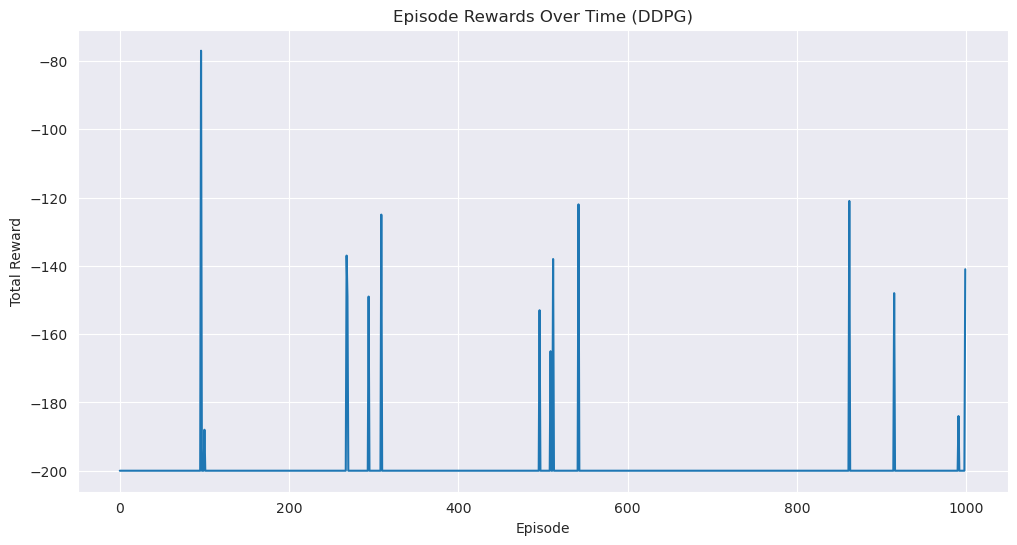

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


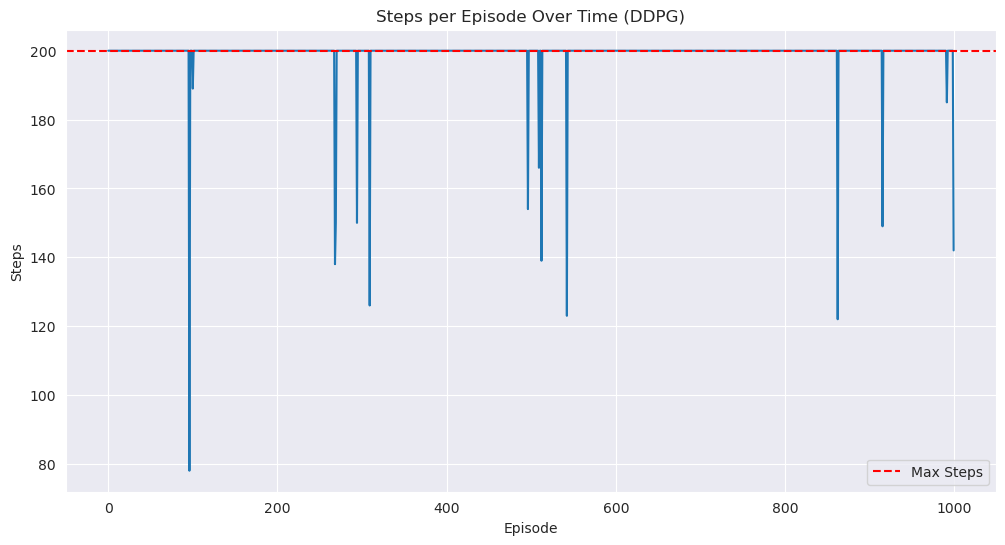

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


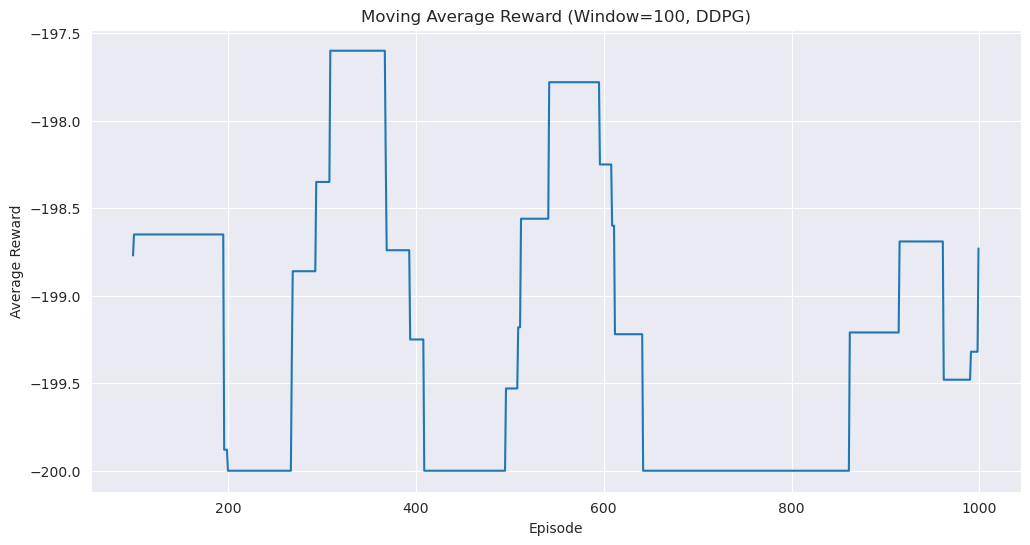

In [13]:
## Plots with Seaborn
sns.set_style('darkgrid')
# Episode rewards
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_rewards)
plt.title('Episode Rewards Over Time (DDPG)')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.show()

# Steps per episode
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_steps)
plt.title('Steps per Episode Over Time (DDPG)')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.axhline(y=200, color='r', linestyle='--', label='Max Steps')
plt.legend()
plt.show()

# Moving average reward
window_size = 100
moving_avg_rewards = np.convolve(episode_rewards, np.ones(window_size)/window_size, mode='valid')
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(window_size-1, n_episodes), y=moving_avg_rewards)
plt.title('Moving Average Reward (Window=100, DDPG)')
plt.xlabel('Episode')
plt.ylabel('Average Reward')
plt.show()

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/gymnasium/spaces/box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


GIF saved successfully as 'mountain_car_ddpg_test.gif'
Test episode: Reached flag: False, Steps taken: 200


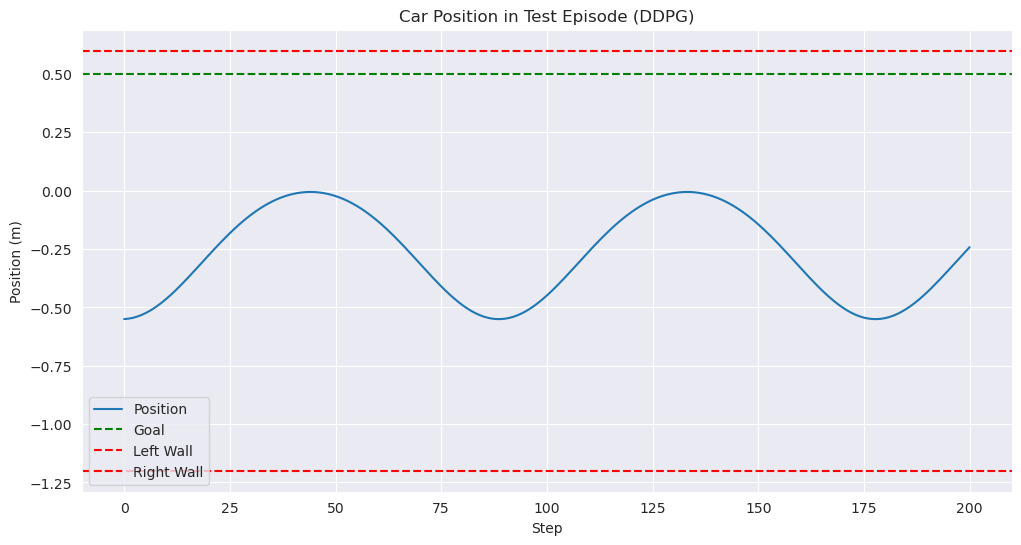

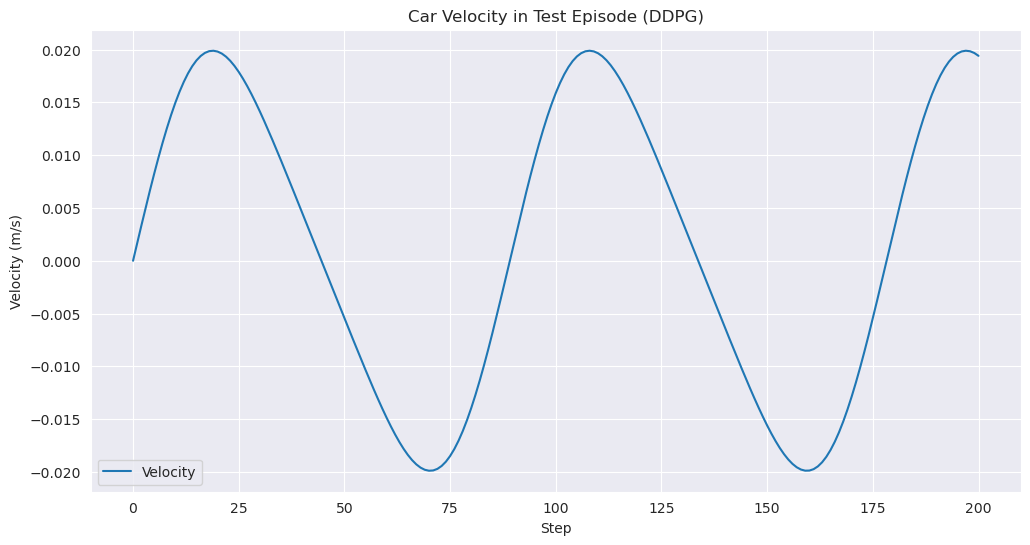

In [14]:
## Test the Trained Model with Rendering and Save as GIF
import imageio.v3 as iio

env_test = CustomMountainCarContinuous(render_mode="rgb_array")
state, _ = env_test.reset()
done = False
steps = 0
frames = []
positions = [env_test.state[0]]
velocities = [env_test.state[1]]

while not done and steps < max_steps:
    norm_state = (state - state_mean) / state_scale
    state_tensor = torch.FloatTensor(norm_state).unsqueeze(0).to(device)
    with torch.no_grad():
        action = actor(state_tensor).cpu().numpy().flatten()
    action_env = np.clip(action, -1.0, 1.0)
    action_env = np.array([action_env], dtype=np.float32).flatten()
    next_state, reward, terminated, truncated, _ = env_test.step(action_env)
    steps += 1
    positions.append(env_test.state[0])
    velocities.append(env_test.state[1])
    frame = env_test.viewer_env.render()
    if frame is not None:
        frames.append(frame)
    state = next_state
    done = terminated or truncated

try:
    iio.imwrite(
        'mountain_car_ddpg_test.gif',
        frames,
        duration=40,
        loop=0
    )
    print("GIF saved successfully as 'mountain_car_ddpg_test.gif'")
except Exception as e:
    print(f"Error saving GIF: {e}")

env_test.close()

reached_flag = terminated
print(f"Test episode: Reached flag: {reached_flag}, Steps taken: {steps}")

plt.figure(figsize=(12, 6))
plt.plot(positions, label='Position')
plt.axhline(y=0.5, color='g', linestyle='--', label='Goal')
plt.axhline(y=-1.2, color='r', linestyle='--', label='Left Wall')
plt.axhline(y=0.6, color='r', linestyle='--', label='Right Wall')
plt.title('Car Position in Test Episode (DDPG)')
plt.xlabel('Step')
plt.ylabel('Position (m)')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(velocities, label='Velocity')
plt.title('Car Velocity in Test Episode (DDPG)')
plt.xlabel('Step')
plt.ylabel('Velocity (m/s)')
plt.legend()
plt.grid(True)
plt.show()



> As we observe, the results are still not satisfying, so we need to both modify environment  + network + hyperparams

In [15]:
# Cell 1: CustomMountainCarContinuous Environment (with Reward Shaping)


class CustomMountainCarContinuous(gym.Env):
    def __init__(self, render_mode=None):
        super().__init__()
        self.action_space = spaces.Box(low=-1.0, high=1.0, shape=(1,), dtype=np.float32)
        self.observation_space = spaces.Box(
            low=np.array([-1.2, -0.07]), high=np.array([0.6, 0.07]), dtype=np.float32
        )
        self.force_multiplier = 0.0015
        self.gravity = 0.0025
        self.max_steps = 200
        self.state = None
        self.step_count = 0
        self.render_mode = render_mode
        self.viewer_env = gym.make("MountainCarContinuous-v0", render_mode=render_mode) if render_mode else None
    
    def step(self, action):
        assert self.action_space.contains(action), f"Invalid action: {action}"
        action = np.clip(action[0], -1.0, 1.0)
        pos, vel = self.state
        self.step_count += 1
        
        vel_next = vel + action * self.force_multiplier - np.cos(3 * pos) * self.gravity
        pos_next = pos + vel_next
        
        if pos_next < -1.2:
            pos_next = -1.2
            vel_next = 0
        elif pos_next > 0.6:
            pos_next = 0.6
            vel_next = 0
        
        self.state = [pos_next, vel_next]
        
        terminated = pos_next >= 0.5
        truncated = self.step_count >= self.max_steps
        # Reward shaping: Base reward + bonus for position and velocity
        reward = -1.0
        if not terminated:
            reward += 0.1 * (pos_next + 0.5) + 0.5 * abs(vel_next)  # Encourage rightward movement and speed
        else:
            reward = 0.0
        
        if self.viewer_env:
            self.viewer_env.unwrapped.state = np.array([pos_next, vel_next], dtype=np.float32)
            self.viewer_env.render()
        
        return np.array(self.state, dtype=np.float32), reward, terminated, truncated, {}
    
    def reset(self, seed=None):
        self.state = [np.random.uniform(-0.6, -0.4), 0.0]
        self.step_count = 0
        if self.viewer_env:
            self.viewer_env.reset(seed=seed)
            self.viewer_env.unwrapped.state = np.array(self.state, dtype=np.float32)
        return np.array(self.state, dtype=np.float32), {}
    
    def close(self):
        if self.viewer_env:
            self.viewer_env.close()

# State normalization parameters
state_mean = np.array([(-1.2 + 0.6) / 2, 0.0])
state_scale = np.array([(0.6 - (-1.2)) / 2, 0.07])

In [16]:
## DDPG with Improved Hyperparameters

# Actor Network
class Actor(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(Actor, self).__init__()
    
        ## Smaller Network
        self.fc1 = nn.Linear(state_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, action_dim)
    
    def forward(self, state):
        x = torch.relu(self.fc1(state))
        x = torch.relu(self.fc2(x))
        return torch.tanh(self.fc3(x))

# Critic Network
class Critic(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(Critic, self).__init__()
     
        # smaller network
        self.fc1 = nn.Linear(state_dim, 64)
        self.fc2 = nn.Linear(64 + action_dim, 32)
        self.fc3 = nn.Linear(32, 1)
    
    def forward(self, state, action):
        x = torch.relu(self.fc1(state))
        x = torch.cat([x, action], dim=1)
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

# Ornstein-Uhlenbeck Noise with Decay
class OUNoise:
    def __init__(self, action_dim, mu=0.0, sigma=0.2, theta=0.15, sigma_decay=0.995, sigma_min=0.05):
        self.action_dim = action_dim
        self.mu = mu
        self.sigma = sigma
        self.theta = theta
        self.sigma_decay = sigma_decay
        self.sigma_min = sigma_min
        self.reset()
    
    def reset(self):
        self.state = np.ones(self.action_dim) * self.mu
    
    def sample(self):
        x = self.state
        dx = self.theta * (self.mu - x) + self.sigma * np.random.randn(len(x))
        self.state = x + dx
        return self.state
    
    def decay(self):
        self.sigma = max(self.sigma_min, self.sigma * self.sigma_decay)

# Replay Buffer
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)
    
    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))
    
    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        state, action, reward, next_state, done = map(np.array, zip(*batch))
        return state, action, reward, next_state, done
    
    def __len__(self):
        return len(self.buffer)

# Parameters
gamma = 0.99
buffer_capacity = 100000
n_episodes = 1000
max_steps = 200
actor_lr = 1e-4  # Reduced for stability
critic_lr = 1e-3
tau = 0.005  # Increased for faster target updates
batch_size = 128  # Increased for stable gradients
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize
env = CustomMountainCarContinuous()
state_dim = 2
action_dim = 1
actor = Actor(state_dim, action_dim).to(device)
target_actor = Actor(state_dim, action_dim).to(device)
target_actor.load_state_dict(actor.state_dict())
critic = Critic(state_dim, action_dim).to(device)
target_critic = Critic(state_dim, action_dim).to(device)
target_critic.load_state_dict(critic.state_dict())
actor_optimizer = optim.Adam(actor.parameters(), lr=actor_lr)
critic_optimizer = optim.Adam(critic.parameters(), lr=critic_lr)
criterion = nn.MSELoss()
replay_buffer = ReplayBuffer(buffer_capacity)
noise = OUNoise(action_dim, mu=0.0, sigma=0.2, sigma_decay=0.995, sigma_min=0.05)

In [17]:
## Training Loop with Improvements
episode_rewards = []
episode_steps = []
successes = []

start_time = time.time()

for episode in range(n_episodes):
    state, _ = env.reset()
    noise.reset()
    total_reward = 0
    steps = 0
    done = False
    
    while not done and steps < max_steps:
        norm_state = (state - state_mean) / state_scale
        state_tensor = torch.FloatTensor(norm_state).unsqueeze(0).to(device)
        
        with torch.no_grad():
            action = actor(state_tensor).cpu().numpy().flatten()
        action = action + noise.sample()
        action = np.clip(action, -1.0, 1.0)
        action_env = np.array([action], dtype=np.float32).flatten()
        
        next_state, reward, terminated, truncated, _ = env.step(action_env)
        total_reward += reward
        steps += 1
        
        replay_buffer.push(state, action, reward, next_state, terminated)
        state = next_state
        done = terminated or truncated
        
        if len(replay_buffer) >= batch_size:
            s, a, r, ns, d = replay_buffer.sample(batch_size)
            
            norm_s = (s - state_mean) / state_scale
            norm_ns = (ns - state_mean) / state_scale
            
            s_tensor = torch.FloatTensor(norm_s).to(device)
            a_tensor = torch.FloatTensor(a).to(device)
            r_tensor = torch.FloatTensor(r).unsqueeze(1).to(device)
            ns_tensor = torch.FloatTensor(norm_ns).to(device)
            d_tensor = torch.FloatTensor(d).unsqueeze(1).to(device)
            
            # Critic update with gradient clipping
            with torch.no_grad():
                next_action = target_actor(ns_tensor)
                target_q = target_critic(ns_tensor, next_action)
                target_q = r_tensor + gamma * target_q * (1 - d_tensor)
            q = critic(s_tensor, a_tensor)
            critic_loss = criterion(q, target_q)
            critic_optimizer.zero_grad()
            critic_loss.backward()
            torch.nn.utils.clip_grad_norm_(critic.parameters(), max_norm=1.0)
            critic_optimizer.step()
            
            # Actor update
            pred_action = actor(s_tensor)
            actor_loss = -critic(s_tensor, pred_action).mean()
            actor_optimizer.zero_grad()
            actor_loss.backward()
            torch.nn.utils.clip_grad_norm_(actor.parameters(), max_norm=1.0)
            actor_optimizer.step()
            
            # Soft update
            for param, target_param in zip(actor.parameters(), target_actor.parameters()):
                target_param.data.copy_(tau * param.data + (1 - tau) * target_param.data)
            for param, target_param in zip(critic.parameters(), target_critic.parameters()):
                target_param.data.copy_(tau * param.data + (1 - tau) * target_param.data)
        
        noise.decay()  # Decay exploration noise
    
    episode_rewards.append(total_reward)
    episode_steps.append(steps)
    successes.append(1 if terminated else 0)
    
    if (episode + 1) % 100 == 0:
        print(f"Episode {episode + 1}: Reward={total_reward:.2f}, Steps={steps}, Sigma={noise.sigma:.3f}")

training_time = time.time() - start_time
env.close()

Episode 100: Reward=-194.88, Steps=200, Sigma=0.050
Episode 200: Reward=-195.20, Steps=200, Sigma=0.050
Episode 300: Reward=-195.31, Steps=200, Sigma=0.050
Episode 400: Reward=-195.26, Steps=200, Sigma=0.050
Episode 500: Reward=-195.63, Steps=200, Sigma=0.050
Episode 600: Reward=-195.79, Steps=200, Sigma=0.050
Episode 700: Reward=-195.15, Steps=200, Sigma=0.050
Episode 800: Reward=-194.63, Steps=200, Sigma=0.050
Episode 900: Reward=-194.00, Steps=200, Sigma=0.050
Episode 1000: Reward=-194.19, Steps=200, Sigma=0.050


In [18]:
## Evaluations and Metrics
avg_reward_last_100 = np.mean(episode_rewards[-100:])
success_rate_last_100 = np.mean(successes[-100:]) * 100
avg_steps_last_100 = np.mean([
    s if succ else max_steps for s, succ in zip(episode_steps[-100:], successes[-100:])
])

print(f"Training time: {training_time:.2f} seconds")
print(f"Average reward (last 100 episodes): {avg_reward_last_100:.2f}")
print(f"Success rate (last 100 episodes): {success_rate_last_100:.2f}%")
print(f"Average steps (last 100 episodes, max if fail): {avg_steps_last_100:.2f}")

Training time: 836.49 seconds
Average reward (last 100 episodes): -194.97
Success rate (last 100 episodes): 0.00%
Average steps (last 100 episodes, max if fail): 200.00


/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


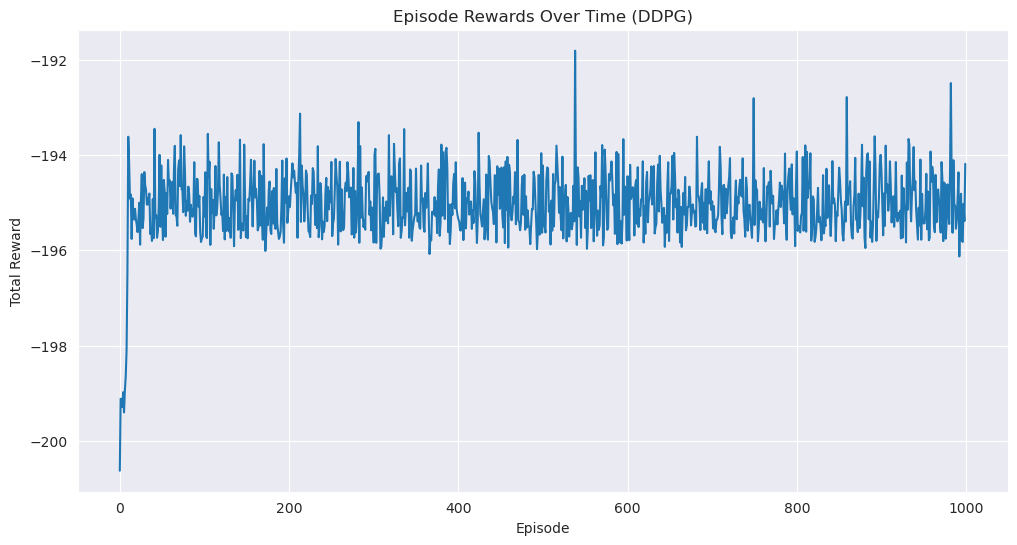

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


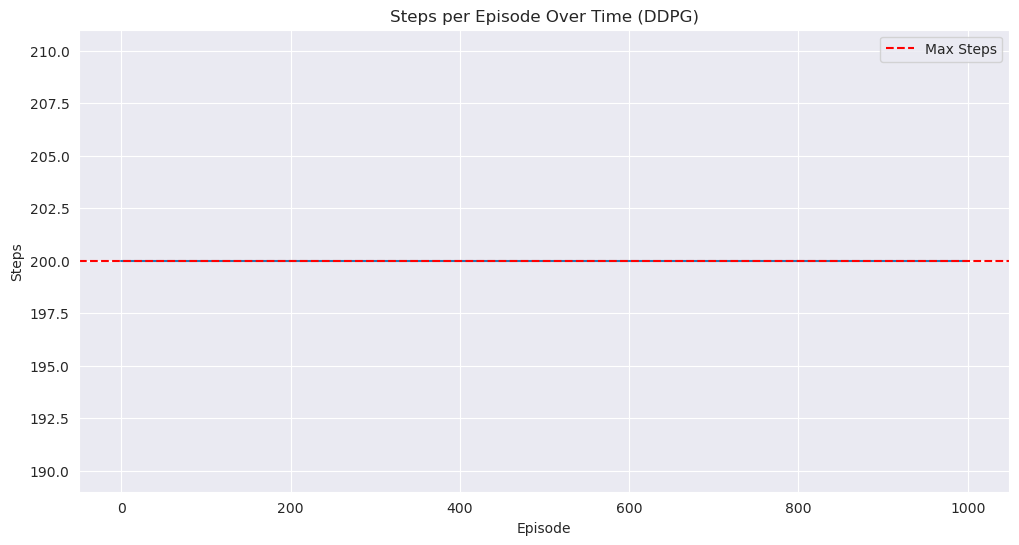

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


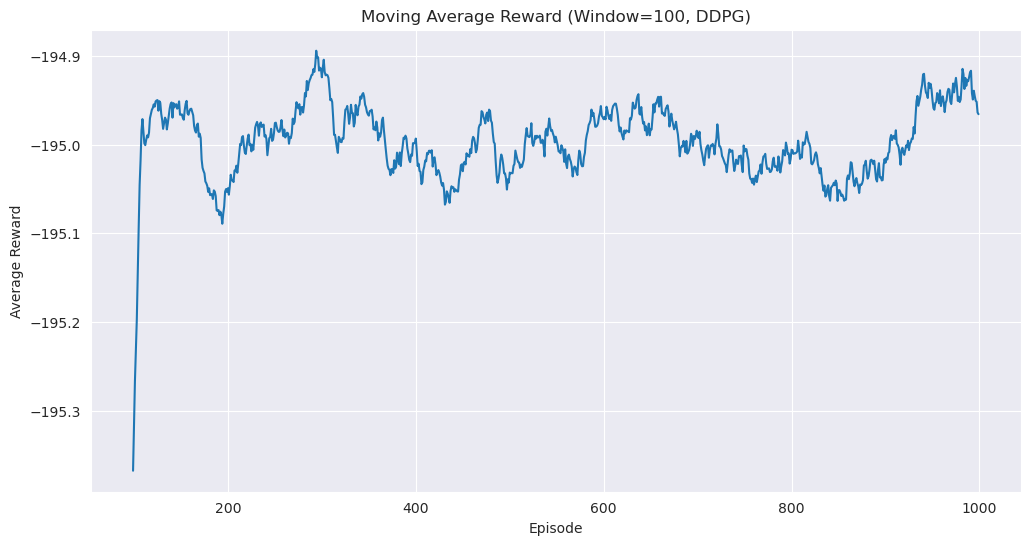

In [19]:


plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_rewards)
plt.title('Episode Rewards Over Time (DDPG)')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.show()

plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_steps)
plt.title('Steps per Episode Over Time (DDPG)')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.axhline(y=200, color='r', linestyle='--', label='Max Steps')
plt.legend()
plt.show()

window_size = 100
moving_avg_rewards = np.convolve(episode_rewards, np.ones(window_size)/window_size, mode='valid')
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(window_size-1, n_episodes), y=moving_avg_rewards)
plt.title('Moving Average Reward (Window=100, DDPG)')
plt.xlabel('Episode')
plt.ylabel('Average Reward')
plt.show()

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/gymnasium/spaces/box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


GIF saved successfully as 'mountain_car_ddpg_test.gif'
Test episode: Reached flag: False, Steps taken: 200


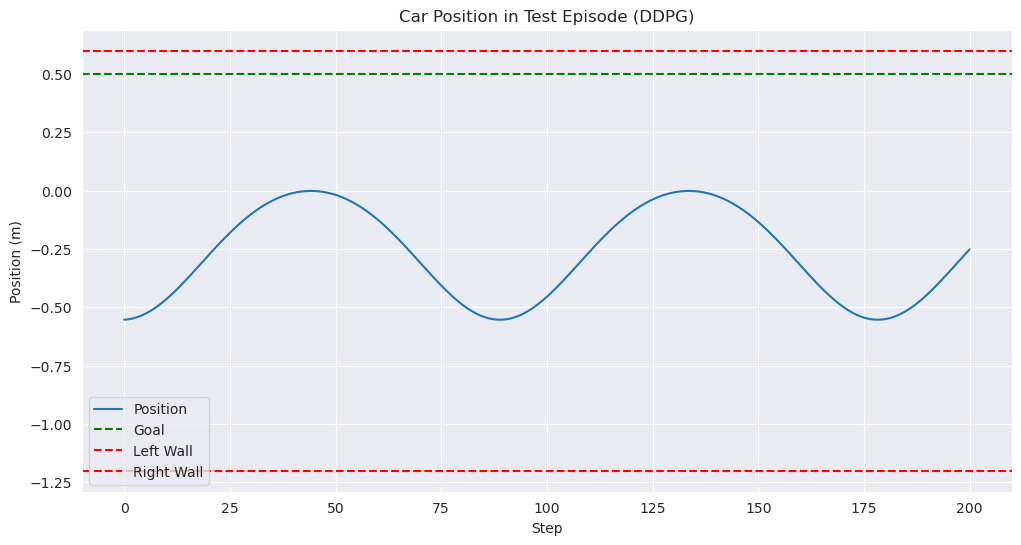

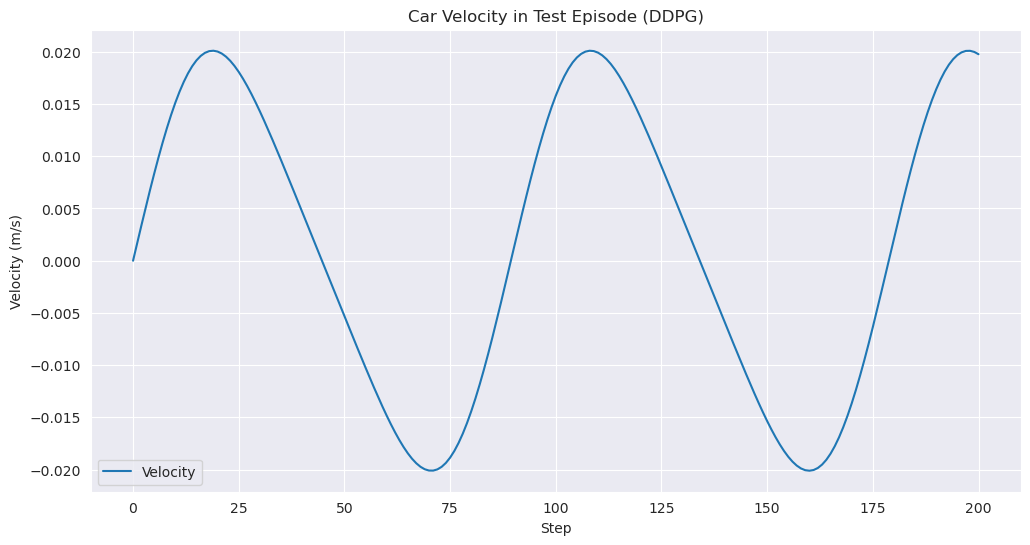

In [20]:


env_test = CustomMountainCarContinuous(render_mode="rgb_array")
state, _ = env_test.reset()
done = False
steps = 0
frames = []
positions = [env_test.state[0]]
velocities = [env_test.state[1]]

while not done and steps < max_steps:
    norm_state = (state - state_mean) / state_scale
    state_tensor = torch.FloatTensor(norm_state).unsqueeze(0).to(device)
    with torch.no_grad():
        action = actor(state_tensor).cpu().numpy().flatten()
    action_env = np.clip(action, -1.0, 1.0)
    action_env = np.array([action_env], dtype=np.float32).flatten()
    next_state, reward, terminated, truncated, _ = env_test.step(action_env)
    steps += 1
    positions.append(env_test.state[0])
    velocities.append(env_test.state[1])
    frame = env_test.viewer_env.render()
    if frame is not None:
        frames.append(frame)
    state = next_state
    done = terminated or truncated

try:
    iio.imwrite(
        'mountain_car_ddpg_test.gif',
        frames,
        duration=40,
        loop=0
    )
    print("GIF saved successfully as 'mountain_car_ddpg_test.gif'")
except Exception as e:
    print(f"Error saving GIF: {e}")

env_test.close()

reached_flag = terminated
print(f"Test episode: Reached flag: {reached_flag}, Steps taken: {steps}")

plt.figure(figsize=(12, 6))
plt.plot(positions, label='Position')
plt.axhline(y=0.5, color='g', linestyle='--', label='Goal')
plt.axhline(y=-1.2, color='r', linestyle='--', label='Left Wall')
plt.axhline(y=0.6, color='r', linestyle='--', label='Right Wall')
plt.title('Car Position in Test Episode (DDPG)')
plt.xlabel('Step')
plt.ylabel('Position (m)')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(velocities, label='Velocity')
plt.title('Car Velocity in Test Episode (DDPG)')
plt.xlabel('Step')
plt.ylabel('Velocity (m/s)')
plt.legend()
plt.grid(True)
plt.show()



> As we see, eventough the reward comes down quickly from -200, it takes a very noisy behaviour after that and not ideal at all.

In [ ]:
## Environment with Enhanced Reward Shaping

class CustomMountainCarContinuous(gym.Env):
    def __init__(self, render_mode=None):
        super().__init__()
        self.action_space = spaces.Box(low=-1.0, high=1.0, shape=(1,), dtype=np.float32)
        self.observation_space = spaces.Box(
            low=np.array([-1.2, -0.07]), high=np.array([0.6, 0.07]), dtype=np.float32
        )
        self.force_multiplier = 0.0015
        self.gravity = 0.0025
        self.max_steps = 200
        self.state = None
        self.step_count = 0
        self.render_mode = render_mode
        self.viewer_env = gym.make("MountainCarContinuous-v0", render_mode=render_mode) if render_mode else None
    
    def step(self, action):
        assert self.action_space.contains(action), f"Invalid action: {action}"
        action = np.clip(action[0], -1.0, 1.0)
        pos, vel = self.state
        self.step_count += 1
        
        vel_next = vel + action * self.force_multiplier - np.cos(3 * pos) * self.gravity
        pos_next = pos + vel_next
        
        if pos_next < -1.2:
            pos_next = -1.2
            vel_next = 0
        elif pos_next > 0.6:
            pos_next = 0.6
            vel_next = 0
        
        self.state = [pos_next, vel_next]
        
        terminated = pos_next >= 0.5
        truncated = self.step_count >= self.max_steps
        # Enhanced reward shaping
        reward = -1.0
        if not terminated:
            reward += 1.0 * (pos_next + 0.5)**2 + 0.5 * abs(vel_next)  ## Modified Reward Function
        else:
            reward += 100.0  # Large bonus for reaching goal
        
        if self.viewer_env:
            self.viewer_env.unwrapped.state = np.array([pos_next, vel_next], dtype=np.float32)
            self.viewer_env.render()
        
        return np.array(self.state, dtype=np.float32), reward, terminated, truncated, {}
    
    def reset(self, seed=None):
        self.state = [np.random.uniform(-0.6, -0.4), 0.0]
        self.step_count = 0
        if self.viewer_env:
            self.viewer_env.reset(seed=seed)
            self.viewer_env.unwrapped.state = np.array(self.state, dtype=np.float32)
        return np.array(self.state, dtype=np.float32), {}
    
    def close(self):
        if self.viewer_env:
            self.viewer_env.close()

# State normalization parameters
state_mean = np.array([(-1.2 + 0.6) / 2, 0.0])
state_scale = np.array([(0.6 - (-1.2)) / 2, 0.07])

In [25]:
## DDPG Setup with even Smaller Network and Tuned Hyperparameters


# Actor Network
class Actor(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(Actor, self).__init__()
        self.fc1 = nn.Linear(state_dim, 64)  # Reduced size
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, action_dim)

    
    def forward(self, state):
        x = torch.relu(self.fc1(state))
        x = torch.relu(self.fc2(x))
        return torch.tanh(self.fc3(x))

# Critic Network
class Critic(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(Critic, self).__init__()
        self.fc1 = nn.Linear(state_dim, 64)
        self.fc2 = nn.Linear(64 + action_dim, 32)
        self.fc3 = nn.Linear(32, 1)
  
    
    def forward(self, state, action):
        x = torch.relu(self.fc1(state))
        x = torch.cat([x, action], dim=1)
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

# Ornstein-Uhlenbeck Noise with Slower Decay
class OUNoise:
    def __init__(self, action_dim, mu=0.0, sigma=0.2, theta=0.15, sigma_decay=0.999, sigma_min=0.1):
        self.action_dim = action_dim
        self.mu = mu
        self.sigma = sigma
        self.theta = theta
        self.sigma_decay = sigma_decay
        self.sigma_min = sigma_min
        self.reset()
    
    def reset(self):
        self.state = np.ones(self.action_dim) * self.mu
    
    def sample(self):
        x = self.state
        dx = self.theta * (self.mu - x) + self.sigma * np.random.randn(len(x))
        self.state = x + dx
        return self.state
    
    def decay(self):
        self.sigma = max(self.sigma_min, self.sigma * self.sigma_decay)

# Replay Buffer
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)
    
    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))
    
    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        state, action, reward, next_state, done = map(np.array, zip(*batch))
        return state, action, reward, next_state, done
    
    def __len__(self):
        return len(self.buffer)

# Parameters
gamma = 0.99
buffer_capacity = 100000
n_episodes = 500
max_steps = 200
actor_lr = 1e-4 ## Different
critic_lr = 1e-3 ## Different
tau = 0.005
batch_size = 128
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize
env = CustomMountainCarContinuous()
state_dim = 2
action_dim = 1
actor = Actor(state_dim, action_dim).to(device)
target_actor = Actor(state_dim, action_dim).to(device)
target_actor.load_state_dict(actor.state_dict())
critic = Critic(state_dim, action_dim).to(device)
target_critic = Critic(state_dim, action_dim).to(device)
target_critic.load_state_dict(critic.state_dict())
actor_optimizer = optim.Adam(actor.parameters(), lr=actor_lr, weight_decay=1e-4)
critic_optimizer = optim.Adam(critic.parameters(), lr=critic_lr, weight_decay=1e-4)
criterion = nn.MSELoss()
replay_buffer = ReplayBuffer(buffer_capacity)
noise = OUNoise(action_dim, mu=0.0, sigma=0.2, sigma_decay=0.999, sigma_min=0.1)

In [26]:
## DDPG Training Loop with Enhanced Stability
episode_rewards = []
episode_steps = []
successes = []

start_time = time.time()

for episode in range(n_episodes):
    state, _ = env.reset()
    noise.reset()
    total_reward = 0
    steps = 0
    done = False
    
    while not done and steps < max_steps:
        norm_state = (state - state_mean) / state_scale
        state_tensor = torch.FloatTensor(norm_state).unsqueeze(0).to(device)
        
        with torch.no_grad():
            action = actor(state_tensor).cpu().numpy().flatten()
        action = action + noise.sample()
        action = np.clip(action, -1.0, 1.0)
        action_env = np.array([action], dtype=np.float32).flatten()
        
        next_state, reward, terminated, truncated, _ = env.step(action_env)
        total_reward += reward
        steps += 1
        
        replay_buffer.push(state, action, reward, next_state, terminated)
        state = next_state
        done = terminated or truncated
        
        if len(replay_buffer) >= batch_size:
            s, a, r, ns, d = replay_buffer.sample(batch_size)
            
            norm_s = (s - state_mean) / state_scale
            norm_ns = (ns - state_mean) / state_scale
            
            s_tensor = torch.FloatTensor(norm_s).to(device)
            a_tensor = torch.FloatTensor(a).to(device)
            r_tensor = torch.FloatTensor(r).unsqueeze(1).to(device)
            ns_tensor = torch.FloatTensor(norm_ns).to(device)
            d_tensor = torch.FloatTensor(d).unsqueeze(1).to(device)
            
            # Multiple critic updates
            for _ in range(2):  # 2 critic updates per step
                with torch.no_grad():
                    next_action = target_actor(ns_tensor)
                    target_q = target_critic(ns_tensor, next_action)
                    target_q = r_tensor + gamma * target_q * (1 - d_tensor)
                q = critic(s_tensor, a_tensor)
                critic_loss = criterion(q, target_q)
                critic_optimizer.zero_grad()
                critic_loss.backward()
                torch.nn.utils.clip_grad_norm_(critic.parameters(), max_norm=1.0)
                critic_optimizer.step()
            
            # Actor update
            pred_action = actor(s_tensor)
            actor_loss = -critic(s_tensor, pred_action).mean()
            actor_optimizer.zero_grad()
            actor_loss.backward()
            torch.nn.utils.clip_grad_norm_(actor.parameters(), max_norm=1.0)
            actor_optimizer.step()
            
            # Soft update
            for param, target_param in zip(actor.parameters(), target_actor.parameters()):
                target_param.data.copy_(tau * param.data + (1 - tau) * target_param.data)
            for param, target_param in zip(critic.parameters(), target_critic.parameters()):
                target_param.data.copy_(tau * param.data + (1 - tau) * target_param.data)
        
        noise.decay()
    
    episode_rewards.append(total_reward)
    episode_steps.append(steps)
    successes.append(1 if terminated else 0)
    
    if (episode + 1) % 100 == 0:
        print(f"Episode {episode + 1}: Reward={total_reward:.2f}, Steps={steps}, Sigma={noise.sigma:.3f}")

training_time = time.time() - start_time
env.close()

Episode 100: Reward=7.01, Steps=112, Sigma=0.100
Episode 200: Reward=40.86, Steps=74, Sigma=0.100
Episode 300: Reward=36.44, Steps=84, Sigma=0.100
Episode 400: Reward=-6.22, Steps=143, Sigma=0.100
Episode 500: Reward=41.16, Steps=72, Sigma=0.100


In [27]:

avg_reward_last_100 = np.mean(episode_rewards[-100:])
success_rate_last_100 = np.mean(successes[-100:]) * 100
avg_steps_last_100 = np.mean([
    s if succ else max_steps for s, succ in zip(episode_steps[-100:], successes[-100:])
])

print(f"Training time: {training_time:.2f} seconds")
print(f"Average reward (last 100 episodes): {avg_reward_last_100:.2f}")
print(f"Success rate (last 100 episodes): {success_rate_last_100:.2f}%")
print(f"Average steps (last 100 episodes, max if fail): {avg_steps_last_100:.2f}")

Training time: 388.45 seconds
Average reward (last 100 episodes): 36.23
Success rate (last 100 episodes): 100.00%
Average steps (last 100 episodes, max if fail): 78.25


/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


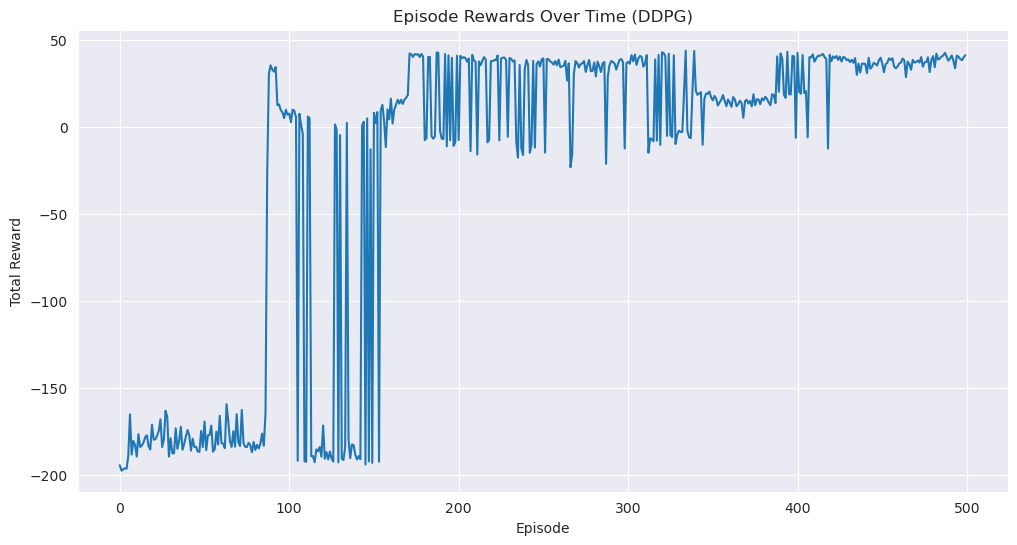

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


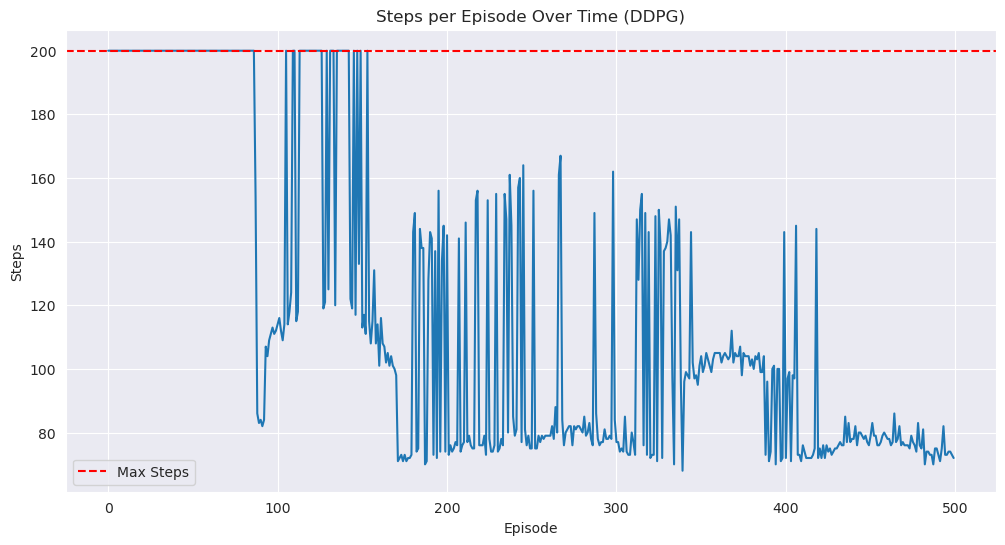

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


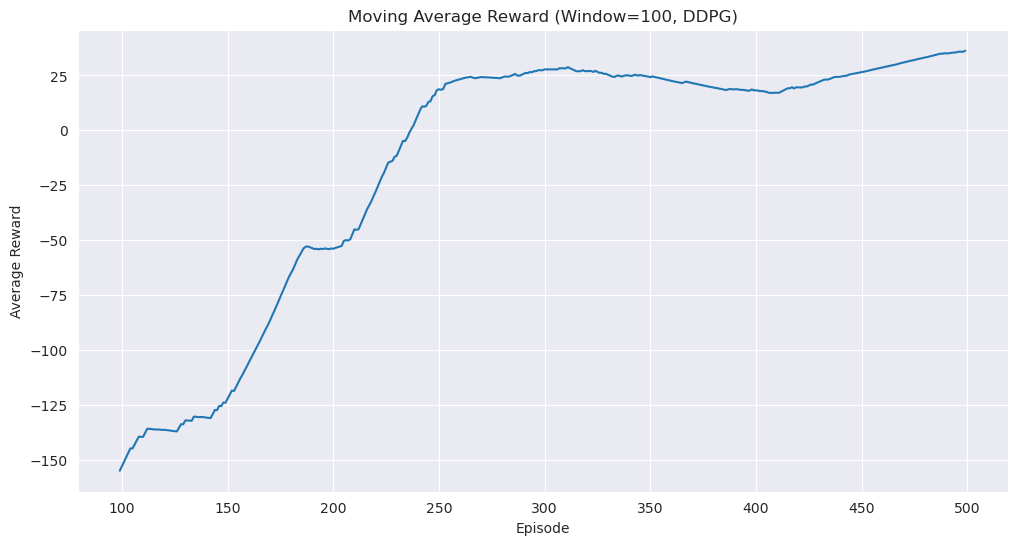

In [28]:

plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_rewards)
plt.title('Episode Rewards Over Time (DDPG)')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.show()

plt.figure(figsize=(12, 6))
sns.lineplot(x=range(n_episodes), y=episode_steps)
plt.title('Steps per Episode Over Time (DDPG)')
plt.xlabel('Episode')
plt.ylabel('Steps')
plt.axhline(y=200, color='r', linestyle='--', label='Max Steps')
plt.legend()
plt.show()

window_size = 100
moving_avg_rewards = np.convolve(episode_rewards, np.ones(window_size)/window_size, mode='valid')
plt.figure(figsize=(12, 6))
sns.lineplot(x=range(window_size-1, n_episodes), y=moving_avg_rewards)
plt.title('Moving Average Reward (Window=100, DDPG)')
plt.xlabel('Episode')
plt.ylabel('Average Reward')
plt.show()

/home/ali/miniconda3/envs/main/lib/python3.10/site-packages/gymnasium/spaces/box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


GIF saved successfully as 'mountain_car_ddpg_test.gif'
Test episode: Reached flag: True, Steps taken: 71


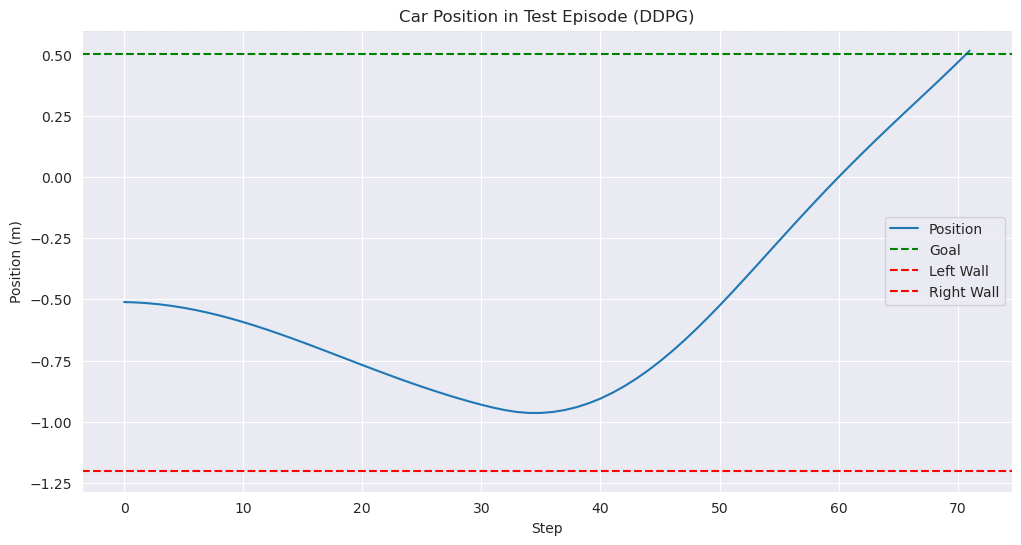

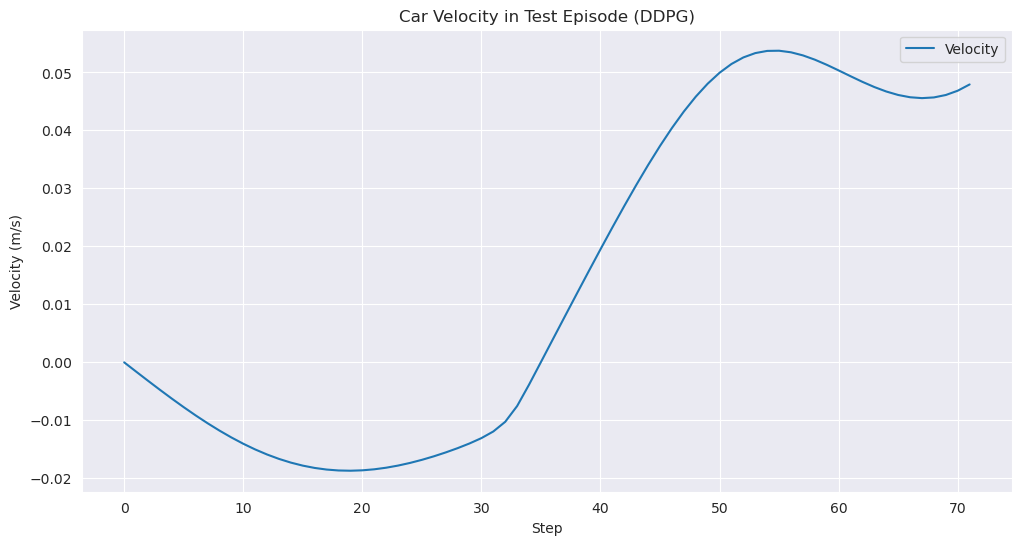

In [29]:


env_test = CustomMountainCarContinuous(render_mode="rgb_array")
state, _ = env_test.reset()
done = False
steps = 0
frames = []
positions = [env_test.state[0]]
velocities = [env_test.state[1]]

while not done and steps < max_steps:
    norm_state = (state - state_mean) / state_scale
    state_tensor = torch.FloatTensor(norm_state).unsqueeze(0).to(device)
    with torch.no_grad():
        action = actor(state_tensor).cpu().numpy().flatten()
    action_env = np.clip(action, -1.0, 1.0)
    action_env = np.array([action_env], dtype=np.float32).flatten()
    next_state, reward, terminated, truncated, _ = env_test.step(action_env)
    steps += 1
    positions.append(env_test.state[0])
    velocities.append(env_test.state[1])
    frame = env_test.viewer_env.render()
    if frame is not None:
        frames.append(frame)
    state = next_state
    done = terminated or truncated

try:
    iio.imwrite(
        'mountain_car_ddpg_test.gif',
        frames,
        duration=40,
        loop=0
    )
    print("GIF saved successfully as 'mountain_car_ddpg_test.gif'")
except Exception as e:
    print(f"Error saving GIF: {e}")

env_test.close()

reached_flag = terminated
print(f"Test episode: Reached flag: {reached_flag}, Steps taken: {steps}")

plt.figure(figsize=(12, 6))
plt.plot(positions, label='Position')
plt.axhline(y=0.5, color='g', linestyle='--', label='Goal')
plt.axhline(y=-1.2, color='r', linestyle='--', label='Left Wall')
plt.axhline(y=0.6, color='r', linestyle='--', label='Right Wall')
plt.title('Car Position in Test Episode (DDPG)')
plt.xlabel('Step')
plt.ylabel('Position (m)')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(velocities, label='Velocity')
plt.title('Car Velocity in Test Episode (DDPG)')
plt.xlabel('Step')
plt.ylabel('Velocity (m/s)')
plt.legend()
plt.grid(True)
plt.show()

